# Семинар 3. Самостоятельная работа: полный анализ scRNA-seq

**Датасет:** 1k Heart Cells from an E18 mouse (v3 chemistry), 10x Genomics, Cell Ranger 3.0.0

**Источник:** https://www.10xgenomics.com/datasets/1-k-heart-cells-from-an-e-18-mouse-v-3-chemistry-3-standard-3-0-0
(файл *Feature / cell matrix HDF5 (filtered)* — `heart_1k_v3_filtered_feature_bc_matrix.h5`)

**Участники:** Семено Мария, Ускенбаева Анель

Цепочка анализа: QC → normalize/log1p → HVG → PCA → kNN → Leiden → маркеры и ручная аннотация → CellTypist → субкластеризация → генные программы → выводы.

In [9]:
%pip install scikit-misc igraph leidenalg celltypist

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=90, frameon=False, figsize=(5, 4.5))
DATA_DIR = Path("data")
SEED = 42

## Задание 1. Данные и контроль качества

**Что за данные.** Клетки целого сердца мыши на 18-й день эмбрионального развития (E18). Сердце диссоциировано до одиночных клеток, ~1000 клеток прочитаны на 10x Chromium (химия v3), выравнивание на геном mm10. Это **демонстрационный набор 10x Genomics**: его выпустили, чтобы показать качество химии v3, поэтому конкретного биологического вопроса у авторов нет. Наш вопрос: **какие клеточные популяции есть в эмбриональном сердце мыши и как их надёжно определить по транскриптому.**

In [11]:
heart = sc.read_10x_h5(DATA_DIR / "heart_1k_v3_filtered_feature_bc_matrix.h5")
heart.var_names_make_unique()
print(f"Клеток: {heart.n_obs}, генов: {heart.n_vars}")

heart.var["mt"] = heart.var_names.str.startswith("mt-")      # у мыши митохондриальные гены — 'mt-'
heart.var["hb"] = heart.var_names.str.match(r"^Hb[ab]-")      # гемоглобины — маркер эритроцитов
sc.pp.calculate_qc_metrics(heart, qc_vars=["mt", "hb"], percent_top=None, inplace=True)

QC = ["total_counts", "n_genes_by_counts", "pct_counts_mt"]
heart.obs[QC + ["pct_counts_hb"]].describe(percentiles=[.01, .5, .99]).round(1)

c:\Users\Lenovo Ideapad 5\AppData\Local\Programs\Python\Python311\Lib\site-packages\anndata\_core\anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
c:\Users\Lenovo Ideapad 5\AppData\Local\Programs\Python\Python311\Lib\site-packages\anndata\_core\anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Клеток: 1011, генов: 31053


,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_hb
count,1011.0,1011.0,1011.0,1011.0
mean,13986.7,2620.7,14.3,13.3
std,15786.7,2152.6,17.3,32.8
min,506.0,17.0,0.0,0.0
1%,609.1,35.0,0.0,0.0
50%,7610.0,2058.0,7.2,0.0
99%,67060.0,7547.5,83.0,98.1
max,122022.0,9452.0,99.0,98.6


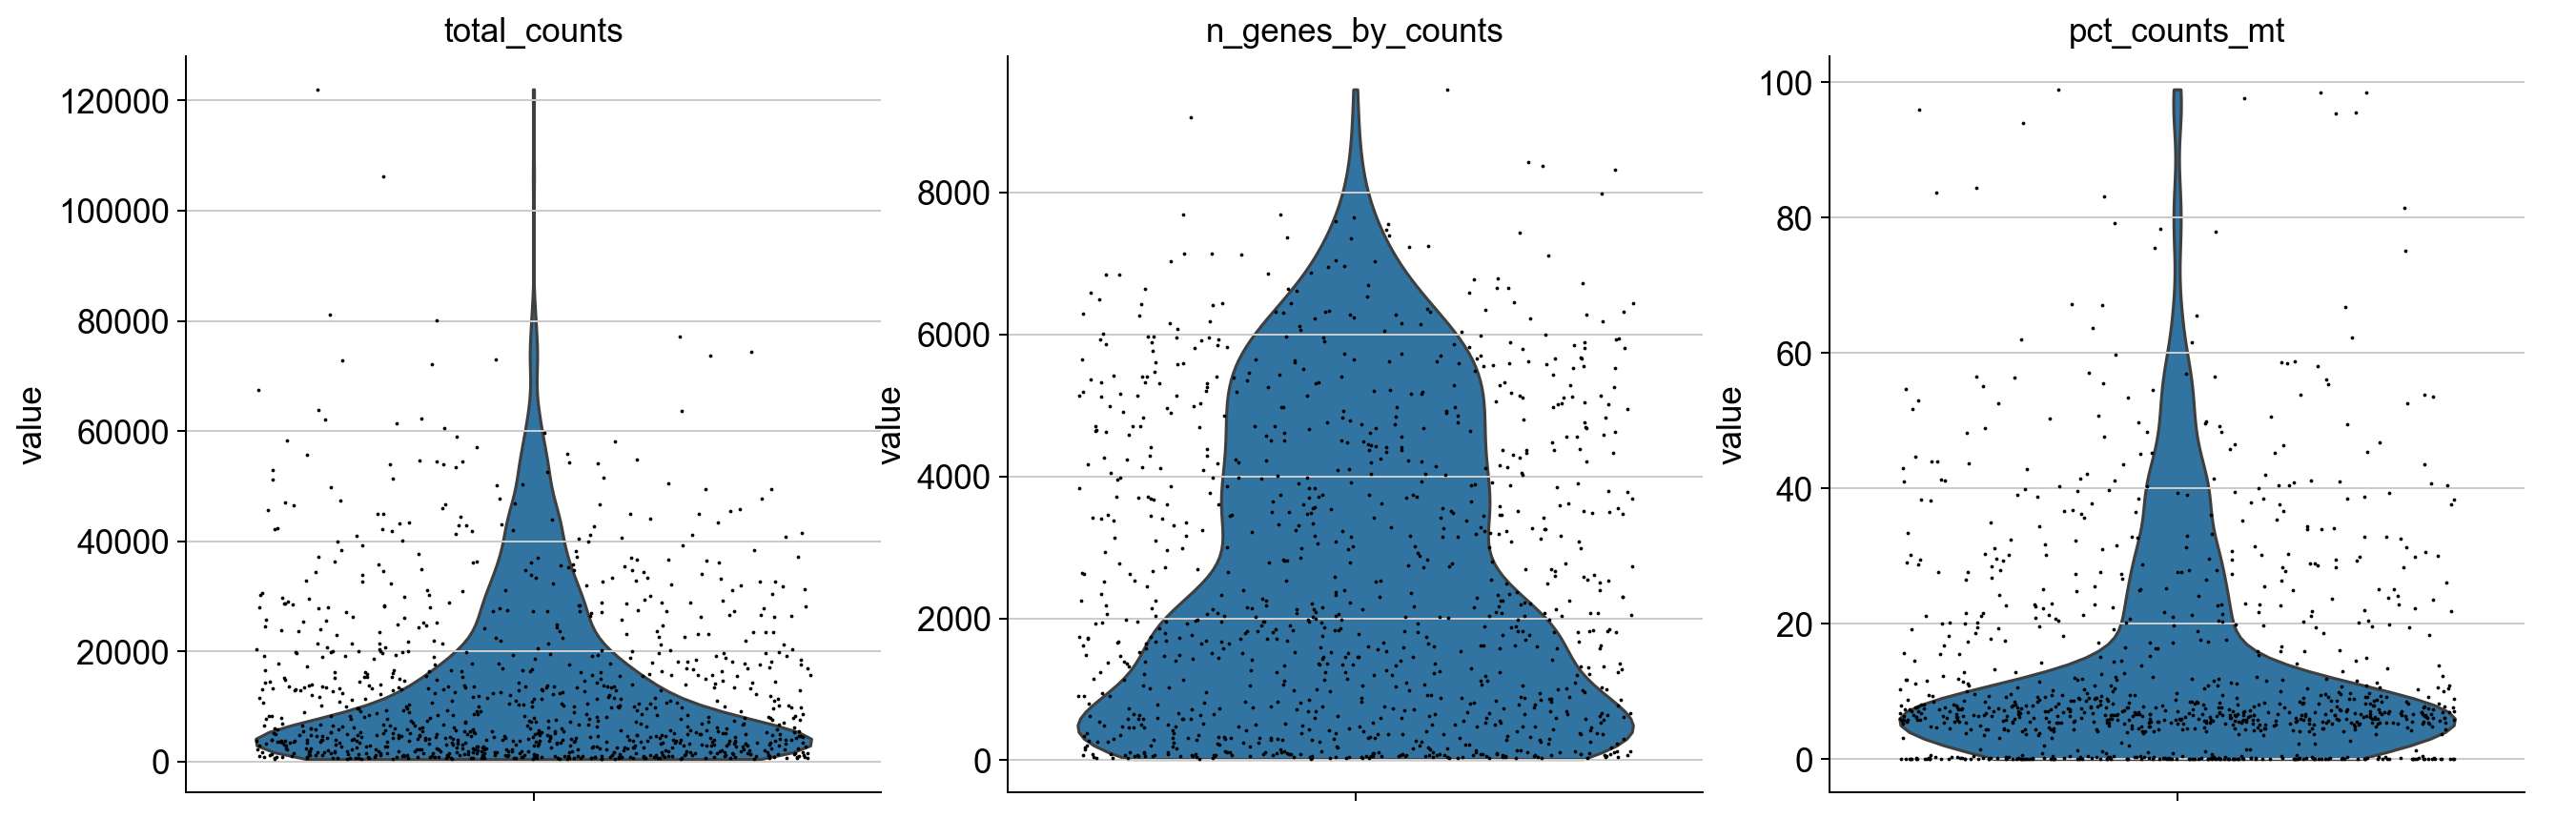

In [12]:
sc.pl.violin(heart, QC, multi_panel=True, jitter=0.4, size=1.5)

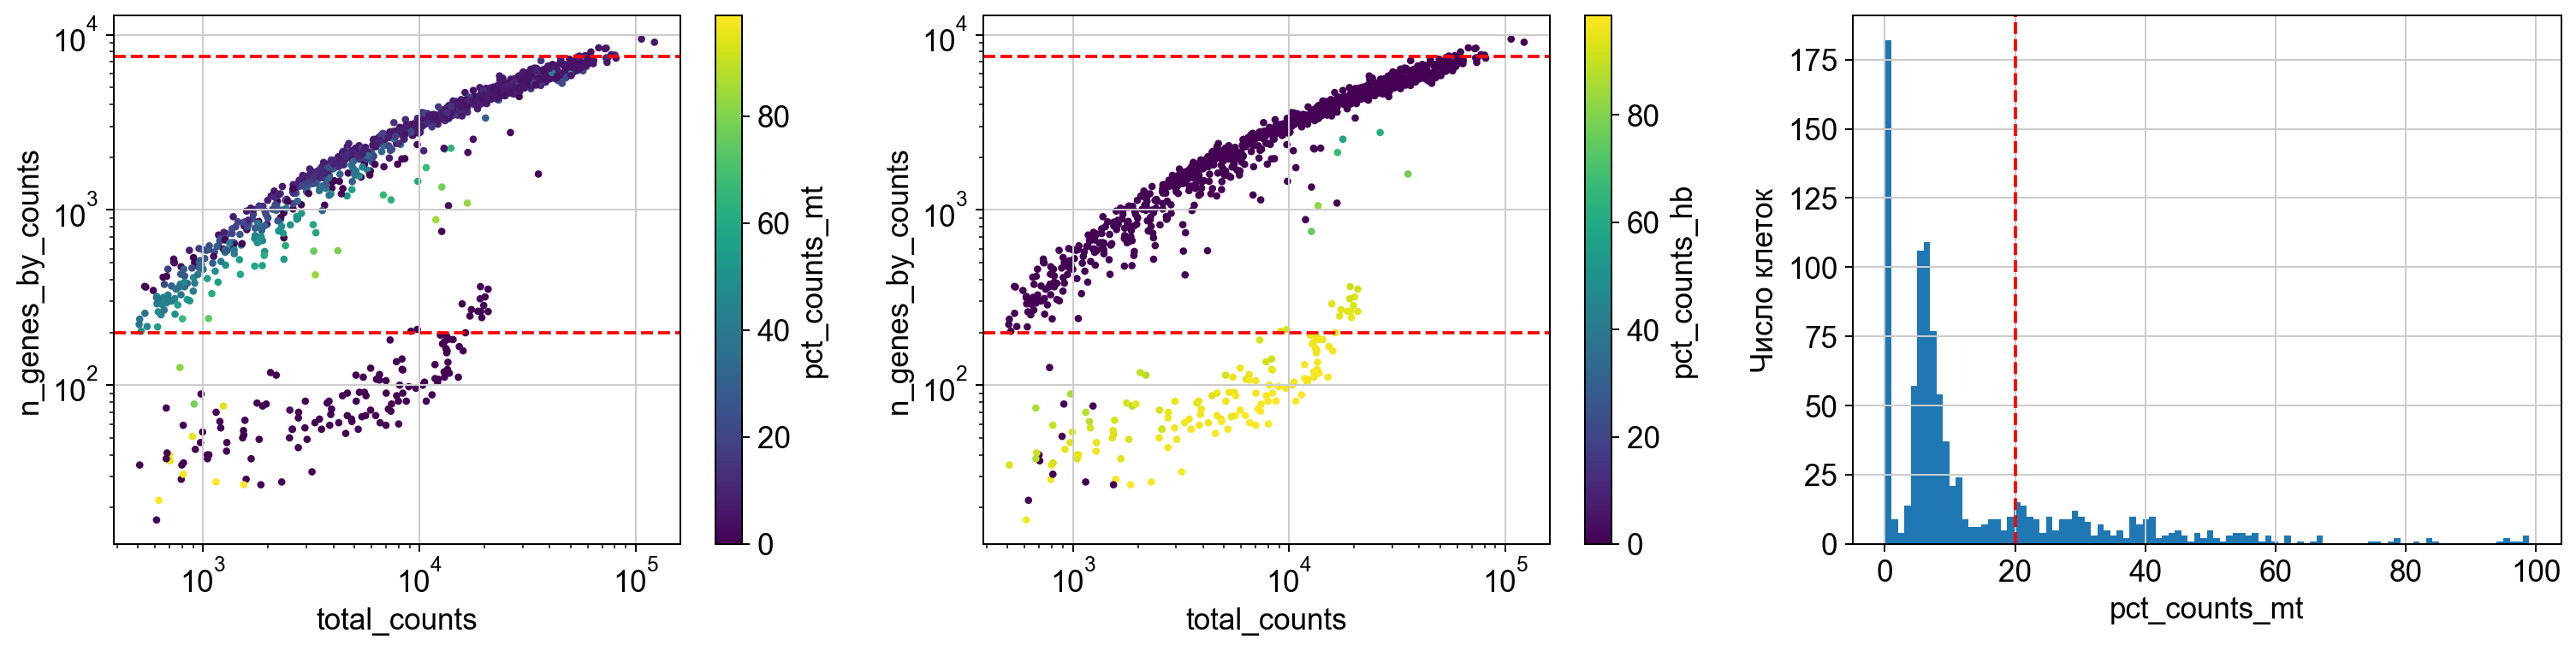

In [13]:
# Пороги фильтрации (обоснование ниже)
MIN_GENES, MAX_GENES, MAX_MT, MIN_CELLS = 200, 7500, 20, 3

o = heart.obs
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
s = axes[0].scatter(o.total_counts, o.n_genes_by_counts, c=o.pct_counts_mt, s=6, cmap="viridis")
plt.colorbar(s, ax=axes[0], label="pct_counts_mt")
s = axes[1].scatter(o.total_counts, o.n_genes_by_counts, c=o.pct_counts_hb, s=6, cmap="viridis")
plt.colorbar(s, ax=axes[1], label="pct_counts_hb")
for ax in axes[:2]:
    ax.set(xscale="log", yscale="log", xlabel="total_counts", ylabel="n_genes_by_counts")
    ax.axhline(MIN_GENES, color="red", ls="--"); ax.axhline(MAX_GENES, color="red", ls="--")
axes[2].hist(o.pct_counts_mt, bins=100); axes[2].axvline(MAX_MT, color="red", ls="--")
axes[2].set(xlabel="pct_counts_mt", ylabel="Число клеток")
plt.tight_layout(); plt.show()

In [14]:
# Кого отсекает каждый порог
low = o.n_genes_by_counts < MIN_GENES
print(f"n_genes < {MIN_GENES}: {low.sum()} клеток; медианная доля Hb у них {o.pct_counts_hb[low].median():.1f}%")
print(f"n_genes > {MAX_GENES}: {(o.n_genes_by_counts > MAX_GENES).sum()} клеток")
bins = pd.cut(o.pct_counts_mt[~low], [0, 5, 10, 20, 30, 50, 100], include_lowest=True)
o[~low].groupby(bins, observed=True).agg(клеток=("total_counts", "size"),
                                         медиана_генов=("n_genes_by_counts", "median")).round(0)

n_genes < 200: 132 клеток; медианная доля Hb у них 95.9%
n_genes > 7500: 11 клеток


,клеток,медиана_генов
pct_counts_mt,,
"(-0.001, 5.0]",146,2046.0
"(5.0, 10.0]",382,4070.0
"(10.0, 20.0]",109,2170.0
"(20.0, 30.0]",96,1480.0
"(30.0, 50.0]",104,662.0
"(50.0, 100.0]",42,682.0


In [15]:
n0, g0 = heart.shape
sc.pp.filter_cells(heart, min_genes=MIN_GENES)
sc.pp.filter_genes(heart, min_cells=MIN_CELLS)
heart = heart[(heart.obs.n_genes_by_counts < MAX_GENES) & (heart.obs.pct_counts_mt < MAX_MT)].copy()
print(f"Клеток: {n0} → {heart.n_obs};  генов: {g0} → {heart.n_vars}")

Клеток: 1011 → 625;  генов: 31053 → 16619


**Выбор порогов.** 

- **`min_genes = 200`.** На scatter видна отдельная нижняя ветвь: тысячи UMI, но меньше ~200–300 генов, и почти все UMI приходятся на гемоглобин (медианная доля Hb у отсекаемых клеток 95.9 %). Это **эритроциты**: у них нет ядра, и транскриптом почти целиком состоит из `Hba`/`Hbb`. Порог убирает 132 такие клетки и единичные пустые капли. Эритроциты попали в образец с кровью сосудов. Из-за почти нулевой сложности транскриптома они плохо нормализуются и раздувают HVG, поэтому основную их массу удаляем. Около 20 эритроцитов чуть выше порога остаются и образуют отдельный кластер.
- **`max_genes = 7500`** (≈ 99-й перцентиль) убирает 11 клеток с максимальной сложностью — кандидатов в **дублеты**. По оценке 10x, при ~1000 клеток доля дублетов около 0.8 %, поэтому отсекаем верхний ~1 %. Отдельного облака дублетов на scatter нет, так что сильнее порог не ужесточаем.
- **`max_mt = 20 %`.** Порог 5 %, как для PBMC, здесь не подходит: в сердце много митохондрий, и основной пик распределения лежит на 5–10 %. При 5 % осталось бы всего 146 клеток. По таблице видно, что после 20 % резко падает число генов: ~4000 при 5–10 % mt, ~1500 при 20–30 % и ~660 при 30–50 %. Это **повреждённые клетки**: цитоплазматическая мРНК вытекла, а митохондриальная осталась.
- **`min_cells = 3`** для генов: ген, найденный в 1–2 клетках, не помогает различать популяции.
- **Итог:** **625 клеток** (из 1011) и **16 619 генов** (из 31 053).

## Задание 2. Нормализация и HVG

Сырые counts сохраняем в `layers["counts"]`: метод `seurat_v3` отбирает HVG именно по counts (моделирует дисперсию отрицательно-биномиального распределения), а `normalize_total` + `log1p` формируют матрицу `.X` для PCA, маркеров и CellTypist.

Выбрано HVG: 2000 из 16619


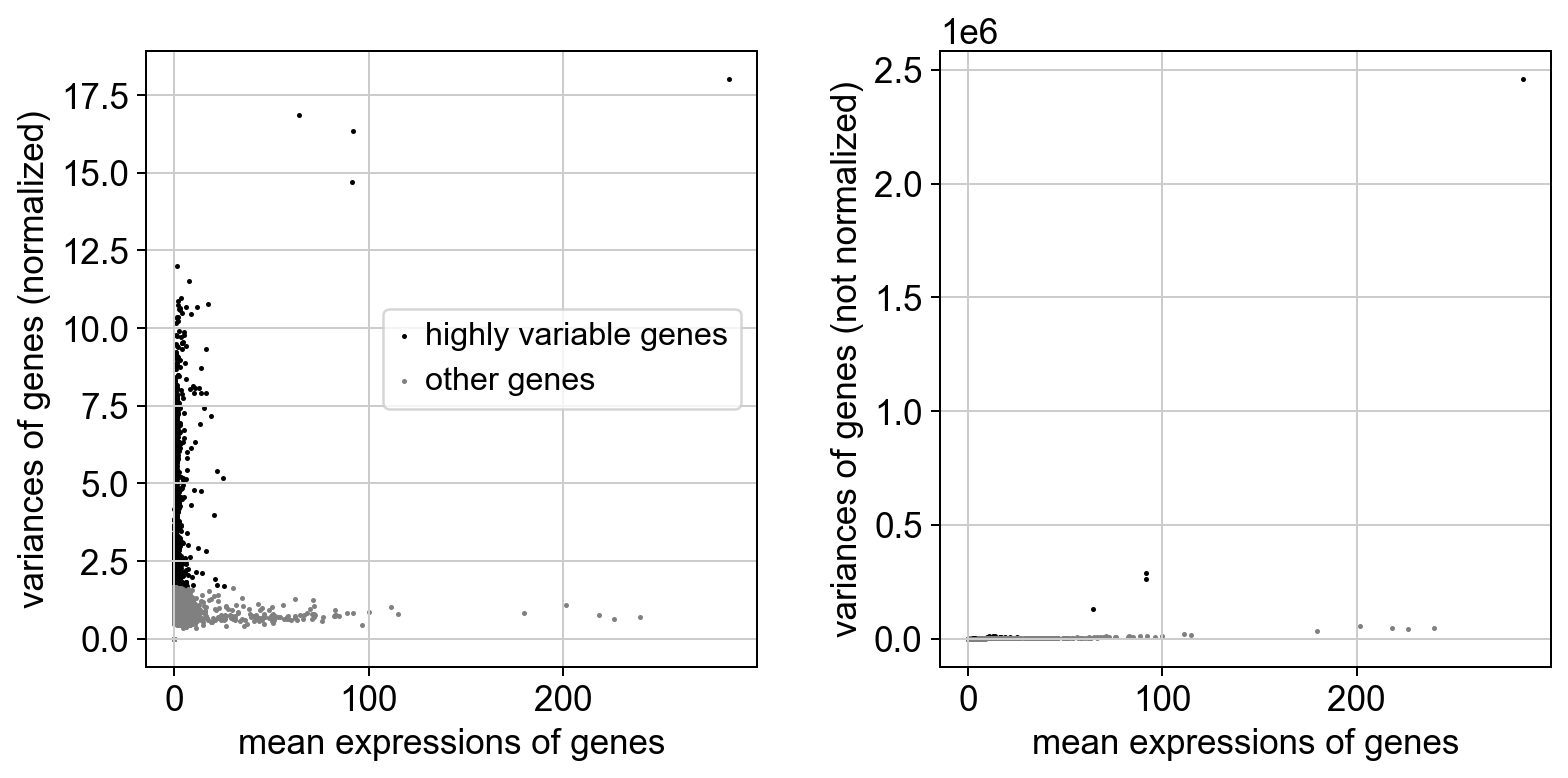

In [16]:
heart.layers["counts"] = heart.X.copy()
sc.pp.normalize_total(heart, target_sum=1e4)
sc.pp.log1p(heart)
sc.pp.highly_variable_genes(heart, layer="counts", flavor="seurat_v3", n_top_genes=2000)

print("Выбрано HVG:", heart.var.highly_variable.sum(), "из", heart.n_vars)
sc.pl.highly_variable_genes(heart)

In [17]:
top10 = heart.var.sort_values("highly_variable_rank").head(10)
top10[["highly_variable_rank", "means", "variances_norm"]].round(2)

,highly_variable_rank,means,variances_norm
Hbb-bs,0.0,285.40,18.03
Hba-a2,1.0,64.28,16.87
Hba-a1,2.0,91.73,16.35
Hbb-bt,3.0,91.50,14.70
Alas2,4.0,1.48,12.02
Krt18,5.0,7.82,11.52
H2-Ab1,6.0,3.38,10.96
Msln,7.0,1.80,10.87
Actc1,8.0,17.10,10.77
Krt19,9.0,2.14,10.73


**Функции топ-10 HVG и зачем нужны HVG.** 

**Функции топ-10 HVG** (по ранжированию `seurat_v3`):

| Ген | Функция | Где экспрессируется |
|---|---|---|
| `Hbb-bs`, `Hbb-bt`, `Hba-a1`, `Hba-a2` | β- и α-глобины, перенос O₂ | эритроциты |
| `Alas2` | эритроидная δ-аминолевулинатсинтаза, первый шаг синтеза гема | эритроидные клетки |
| `Krt18`, `Krt19` | кератины промежуточных филаментов однослойного эпителия | эпителий тимуса, эпикард (мезотелий) |
| `H2-Ab1` | β-цепь MHC класса II, презентация антигена CD4⁺ T-клеткам | эпителий тимуса, макрофаги |
| `Msln` | мезотелин, поверхностный белок мезотелия | эпикард |
| `Actc1` | сердечный α-актин, тонкие филаменты саркомера | кардиомиоциты |

Все десять генов специфичны для отдельных популяций: включены в одном типе клеток и выключены в остальных. Именно такой вклад даёт высокую нормированную дисперсию. Гемоглобины на первых местах из-за ~20 оставшихся эритроцитов с огромной экспрессией: даже небольшая популяция с очень сильным сигналом поднимает гены в топ HVG.

**Зачем отбирать HVG.** Большинство генов либо почти не детектируются в отдельной клетке, либо экспрессируются ровно во всех клетках (гены «домашнего хозяйства»). Их разброс — технический шум выборки UMI, а не биология. Если подать в PCA все 16 619 генов, этот шум растворит сигнал в первых компонентах. HVG (2000 из 16 619) оставляют гены, вариабельность которых превышает ожидаемую при их среднем уровне, — именно они различают типы клеток. Заодно уменьшается размерность и ускоряются вычисления. Остальные гены мы не удаляем: они нужны для поиска маркеров, CellTypist и генных программ.

## Задание 3. PCA и кластеризация

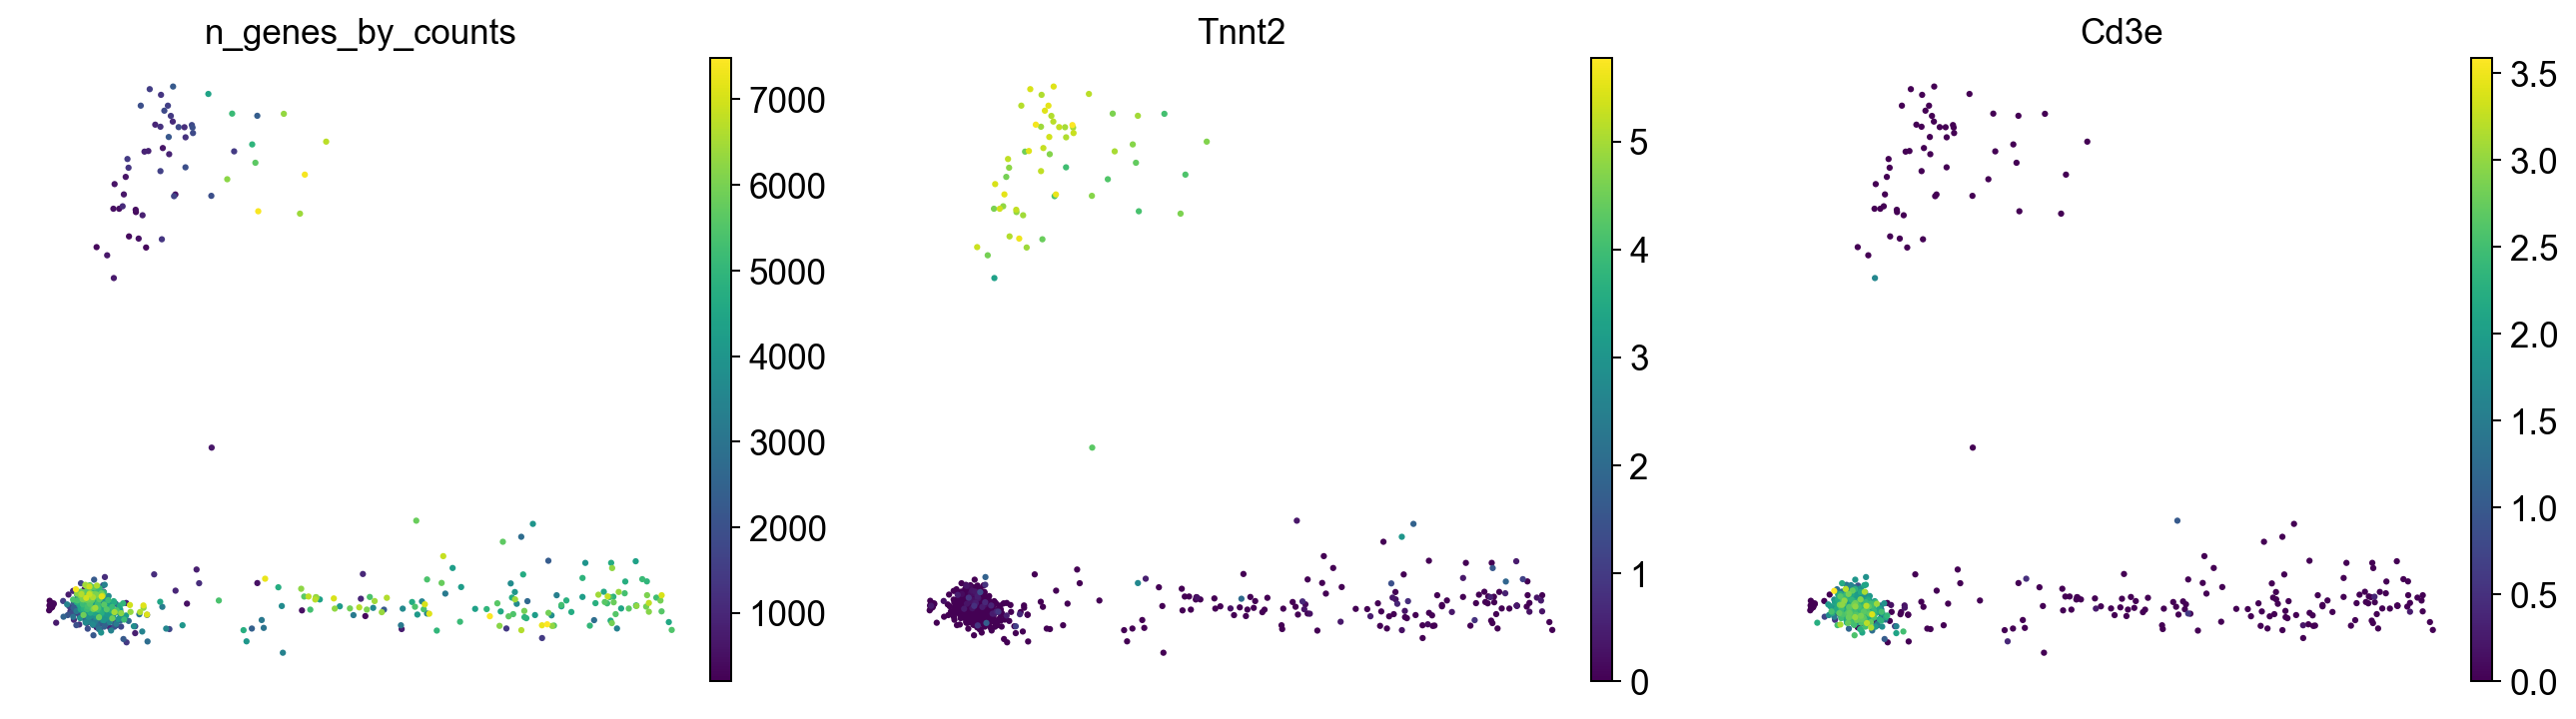

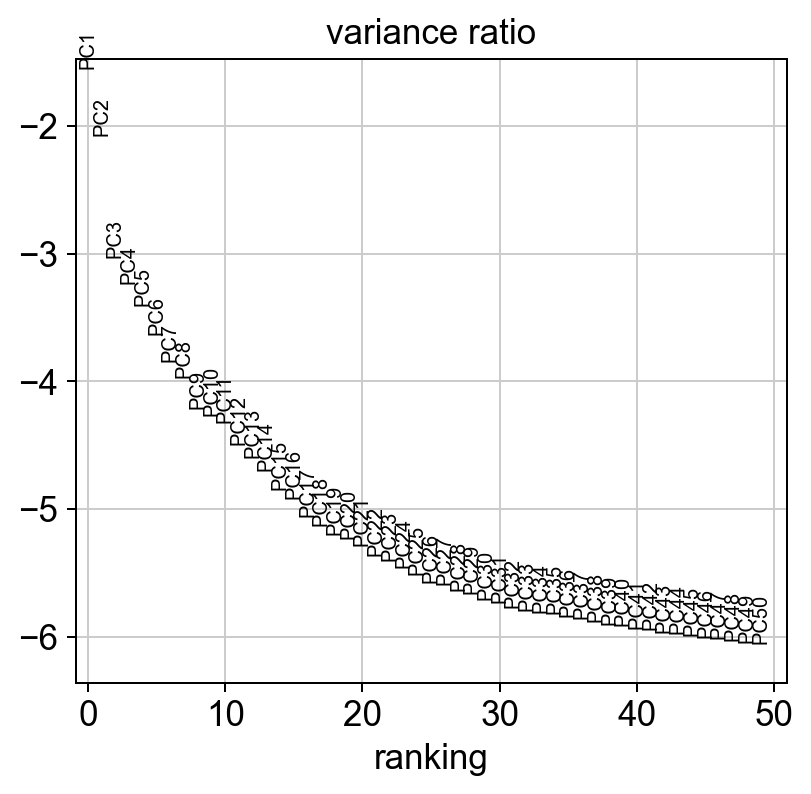

In [18]:
sc.tl.pca(heart, n_comps=50, mask_var="highly_variable", random_state=SEED)
sc.pl.pca(heart, color=["n_genes_by_counts", "Tnnt2", "Cd3e"], ncols=3, size=25)
sc.pl.pca_variance_ratio(heart, n_pcs=50, log=True)

c:\Users\Lenovo Ideapad 5\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Не удается найти указанный файл
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Lenovo Ideapad 5\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Lenovo Ideapad 5\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Lenovo Ideapad 5\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, exe

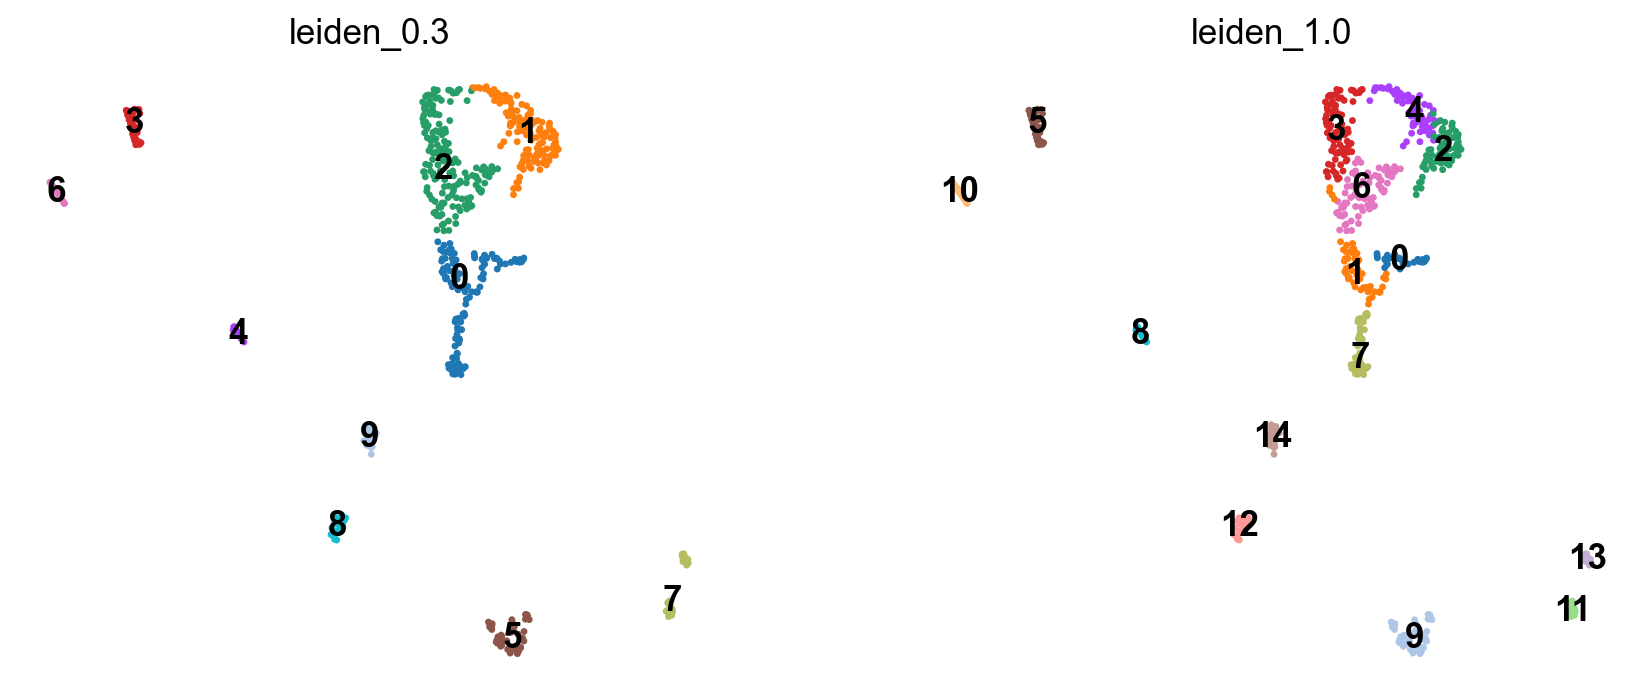

In [19]:
N_PCS = 15   # «локоть» графика: после ~PC15 каждая компонента добавляет < 1% дисперсии
sc.pp.neighbors(heart, n_neighbors=15, n_pcs=N_PCS, random_state=SEED)
sc.tl.umap(heart, min_dist=0.3, random_state=SEED)

RESOLUTIONS = (0.3, 1.0)
for r in RESOLUTIONS:
    # flavor="igraph" — рекомендуемая реализация Leiden в Scanpy
    sc.tl.leiden(heart, resolution=r, key_added=f"leiden_{r}", flavor="igraph",
                 n_iterations=2, directed=False, random_state=0)

sc.pl.umap(heart, color=[f"leiden_{r}" for r in RESOLUTIONS], legend_loc="on data", size=30, ncols=2)

In [20]:
for r in RESOLUTIONS:
    sizes = heart.obs[f"leiden_{r}"].value_counts().sort_index()
    print(f"resolution={r}: {len(sizes)} кластеров, размеры: {sizes.tolist()}")

# Какие кластеры 0.3 распались при 1.0
pd.crosstab(heart.obs["leiden_0.3"], heart.obs["leiden_1.0"],
            rownames=["leiden 0.3"], colnames=["leiden 1.0"])

resolution=0.3: 10 кластеров, размеры: [124, 129, 168, 35, 20, 52, 21, 29, 24, 23]
resolution=1.0: 15 кластеров, размеры: [31, 55, 71, 85, 60, 35, 77, 42, 20, 52, 21, 15, 24, 14, 23]


leiden 1.0,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
leiden 0.3,,,,,,,,,,,,,,,
0,31,51,0,0,0,0,0,42,0,0,0,0,0,0,0
1,0,0,71,0,58,0,0,0,0,0,0,0,0,0,0
2,0,4,0,85,2,0,77,0,0,0,0,0,0,0,0
3,0,0,0,0,0,35,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,20,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,52,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,21,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,0,15,0,14,0
8,0,0,0,0,0,0,0,0,0,0,0,0,24,0,0


**Выводы.** 

- **Число кластеров растёт с `resolution`:** при 0.3 — **10 кластеров** (124, 130, 167, 35, 20, 52, 21, 29, 24, 23 клетки), при 1.0 — **15** (от 14 до 86 клеток). Больший `resolution` сильнее «штрафует» крупные сообщества в модулярности, поэтому они дробятся.
- **Что разделилось** (таблица сопряжённости):
  - кластер 0 (124) → 34 + 38 + 52;
  - кластер 1 (130) → 66 + 59 (+5);
  - кластер 2 (167) → 76 + 86 (+5);
  - эндотелий, кластер 7 (29) → 15 + 14.
  Остальные небольшие кластеры (кардиомиоциты, эритроциты, фибробласты, эпикард, эпителий тимуса) не изменились: это компактные, хорошо отделённые группы.
- **Не каждый кластер — отдельный тип клеток.** Кластеры 0–2 — одно непрерывное облако T-клеток, и при 1.0 оно дробится в основном по состоянию (фаза клеточного цикла, стадия созревания), а не по типу. Разделение эндотелия на две части по 14–15 клеток может отражать подтипы (например, эндокард и сосудистый эндотелий), но для 29 клеток это нужно проверять маркерами. Кластер — это группа в графе соседей, а её биологический смысл устанавливается только аннотацией.

## Задание 4. Ручная аннотация

Дальше работаем с `leiden_0.3`. При этом разрешении все небольшие популяции уже отделены, а при 1.0 дробятся в основном похожие T-клетки и маленькие группы по 14–15 клеток (см. задание 3).

In [21]:
CLUSTER_KEY = "leiden_0.3"
sc.tl.rank_genes_groups(heart, groupby=CLUSTER_KEY, method="wilcoxon", reference="rest",
                        use_raw=False, tie_correct=True, corr_method="benjamini-hochberg",
                        pts=True, key_added="wilcoxon")

# Топ-5 маркеров каждого кластера: logFC и доля экспрессирующих клеток в кластере / вне его
rows = []
for cl in heart.obs[CLUSTER_KEY].cat.categories:
    df = sc.get.rank_genes_groups_df(heart, group=cl, key="wilcoxon").head(5)
    rows.append({"кластер": cl,
                 "клеток": int((heart.obs[CLUSTER_KEY] == cl).sum()),
                 "топ-5 генов (logFC; доля в кластере / вне)": ", ".join(
                     f"{r.names} ({r.logfoldchanges:.1f}; {r.pct_nz_group:.0%}/{r.pct_nz_reference:.0%})"
                     for r in df.itertuples())})
pd.set_option("display.max_colwidth", None)
pd.DataFrame(rows).set_index("кластер")

c:\Users\Lenovo Ideapad 5\AppData\Local\Programs\Python\Python311\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:380: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
c:\Users\Lenovo Ideapad 5\AppData\Local\Programs\Python\Python311\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:380: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
c:\Users\Lenovo Ideapad 5\AppData\Local\Programs\Python\Python311\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:380: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
c:\Users\Lenovo Ideapad 5\AppData\Local\Programs\Python\Python311\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:380: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
c:\Users\Lenovo Ideapad 5\AppData\Local\Programs\Python\Python311\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:380: RuntimeWarning: invalid value encountered in divide
  sc

,клеток,топ-5 генов (logFC; доля в кластере / вне)
кластер,,
0,124,"Nkg7 (6.6; 64%/2%), Tcrg-C2 (5.1; 73%/7%), Plac8 (4.7; 83%/15%), Pld4 (5.4; 64%/4%), Khdc1a (7.0; 53%/1%)"
1,129,"Satb1 (3.1; 97%/65%), Cd8b1 (3.4; 91%/41%), mt-Co1 (1.5; 99%/94%), Znrf1 (2.7; 88%/67%), Lck (2.3; 94%/58%)"
2,168,"Hmgb2 (3.2; 100%/86%), Pclaf (4.1; 95%/25%), Top2a (4.0; 97%/29%), Birc5 (3.7; 94%/25%), Mki67 (3.6; 96%/26%)"
3,35,"Mb (10.4; 91%/2%), Myoz2 (7.2; 94%/4%), Pln (9.1; 100%/5%), Smpx (6.6; 94%/4%), Kcne1 (10.6; 51%/0%)"
4,20,"Alas2 (12.1; 100%/1%), Gypa (11.4; 80%/0%), Snca (9.6; 95%/1%), Rec114 (7.3; 75%/2%), Tspo2 (9.9; 45%/0%)"
5,52,"Aspn (10.3; 69%/1%), Postn (8.2; 92%/6%), Col6a3 (6.2; 88%/5%), Col6a2 (6.0; 90%/7%), Col6a1 (6.3; 92%/8%)"
6,21,"Sln (13.3; 95%/1%), Mybphl (9.2; 81%/1%), Myl1 (11.1; 90%/1%), Fgf12 (9.3; 81%/1%), Ankrd1 (8.7; 100%/5%)"
7,29,"Cdh5 (10.4; 100%/1%), Tie1 (10.4; 97%/0%), Sox18 (10.0; 93%/1%), Adgrl4 (9.8; 83%/0%), Gpr182 (10.0; 86%/1%)"
8,24,"Lrrn4 (13.5; 100%/0%), Muc16 (10.9; 100%/0%), Tmem151a (10.4; 100%/0%), Upk3b (12.8; 100%/0%), Upk1b (10.5; 100%/1%)"


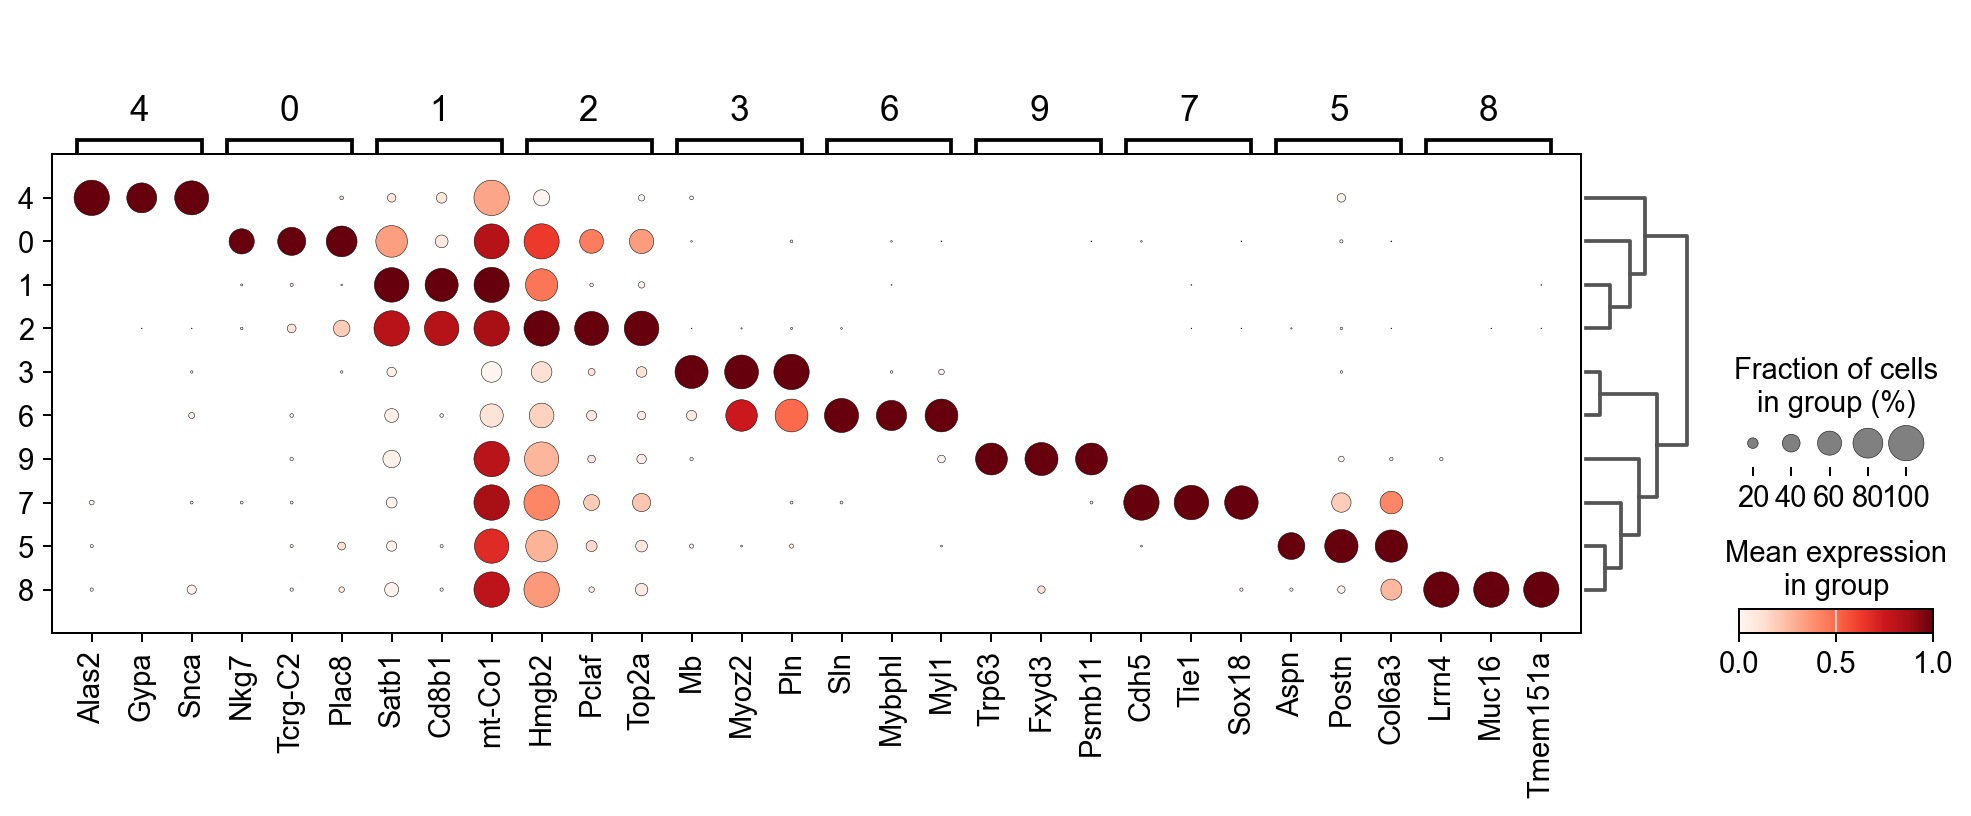

In [22]:
sc.pl.rank_genes_groups_dotplot(heart, key="wilcoxon", groupby=CLUSTER_KEY, n_genes=3,
                                use_raw=False, standard_scale="var")

**Маркеры из литературы** для проверки гипотез, выдвинутых по топ-генам:

| Популяция | Гены | Источник / обоснование |
|---|---|---|
| Кардиомиоциты (КМ) | `Tnnt2`, `Actc1` | сердечный тропонин T и сердечный актин |
| КМ желудочков | `Myl2`, `Myl3` | лёгкие цепи миозина желудочков |
| КМ предсердий | `Myl7`, `Nppa`, `Sln` | предсердные миозин, натрийуретический пептид и сарколипин |
| Фибробласты | `Col1a1`, `Pdgfra`, `Postn` | коллаген I, PDGFRα — классический маркер фибробластов сердца |
| Эндотелий | `Cdh5`, `Pecam1`, `Emcn` | VE-кадгерин, CD31, эндомуцин |
| Эпикард (мезотелий) | `Upk3b`, `Msln`, `Wt1` | маркеры мезотелия / эпикарда |
| Эритроциты | `Hbb-bs`, `Alas2`, `Gypa` | гемоглобин, синтез гема, гликофорин A |
| T-клетки | `Cd3e`, `Lck` | TCR-комплекс |
| Тимоциты DP | `Cd8a`, `Cd4`, `Rag1` | CD4⁺CD8⁺ с перестройкой TCR |
| γδ T / DN тимоциты | `Trdc`, `Il2ra` | цепь δ TCR, CD25 (DN2–DN3 стадии) |
| Эпителий тимуса | `Krt8`, `Psmb11`, `Foxn1` | кератин эпителия, тимопротеасома кортикального эпителия, мастер-регулятор TEC |
| Деление | `Top2a`, `Mki67` | пролиферация |

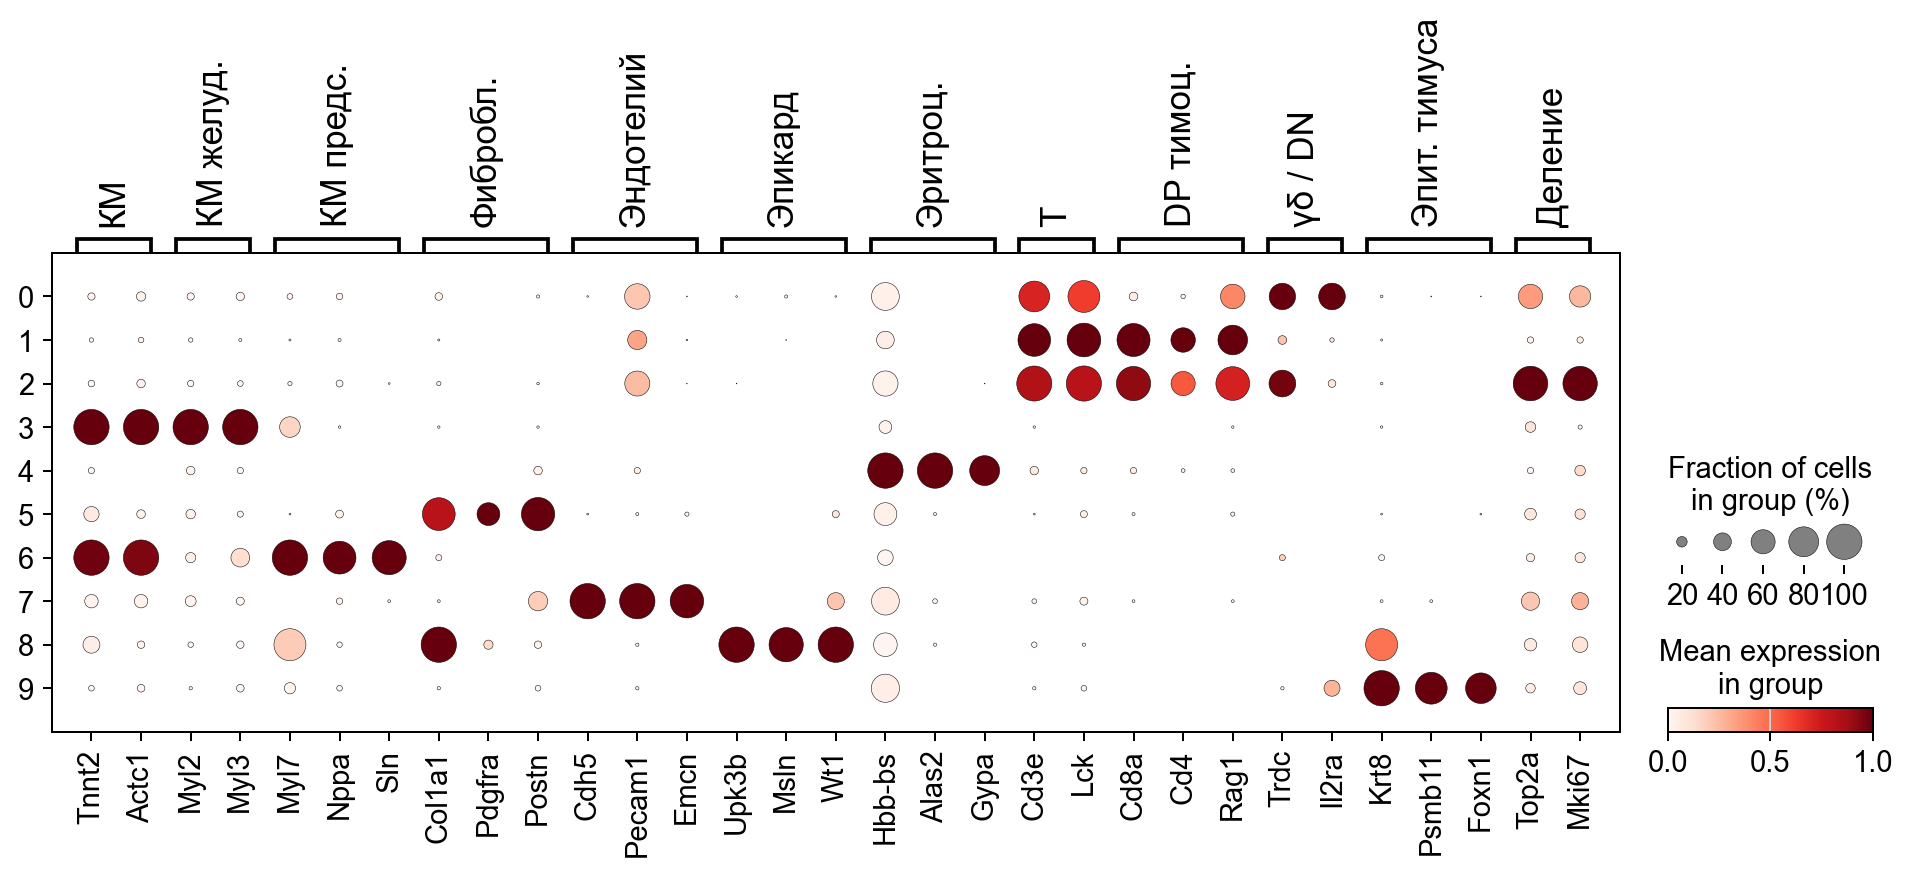

In [23]:
LIT_MARKERS = {
    "КМ": ["Tnnt2", "Actc1"],
    "КМ желуд.": ["Myl2", "Myl3"],
    "КМ предс.": ["Myl7", "Nppa", "Sln"],
    "Фибробл.": ["Col1a1", "Pdgfra", "Postn"],
    "Эндотелий": ["Cdh5", "Pecam1", "Emcn"],
    "Эпикард": ["Upk3b", "Msln", "Wt1"],
    "Эритроц.": ["Hbb-bs", "Alas2", "Gypa"],
    "T": ["Cd3e", "Lck"],
    "DP тимоц.": ["Cd8a", "Cd4", "Rag1"],
    "γδ / DN": ["Trdc", "Il2ra"],
    "Эпит. тимуса": ["Krt8", "Psmb11", "Foxn1"],
    "Деление": ["Top2a", "Mki67"],
}
LIT_MARKERS = {k: [g for g in v if g in heart.var_names] for k, v in LIT_MARKERS.items()}
sc.pl.dotplot(heart, LIT_MARKERS, groupby=CLUSTER_KEY, standard_scale="var", use_raw=False)

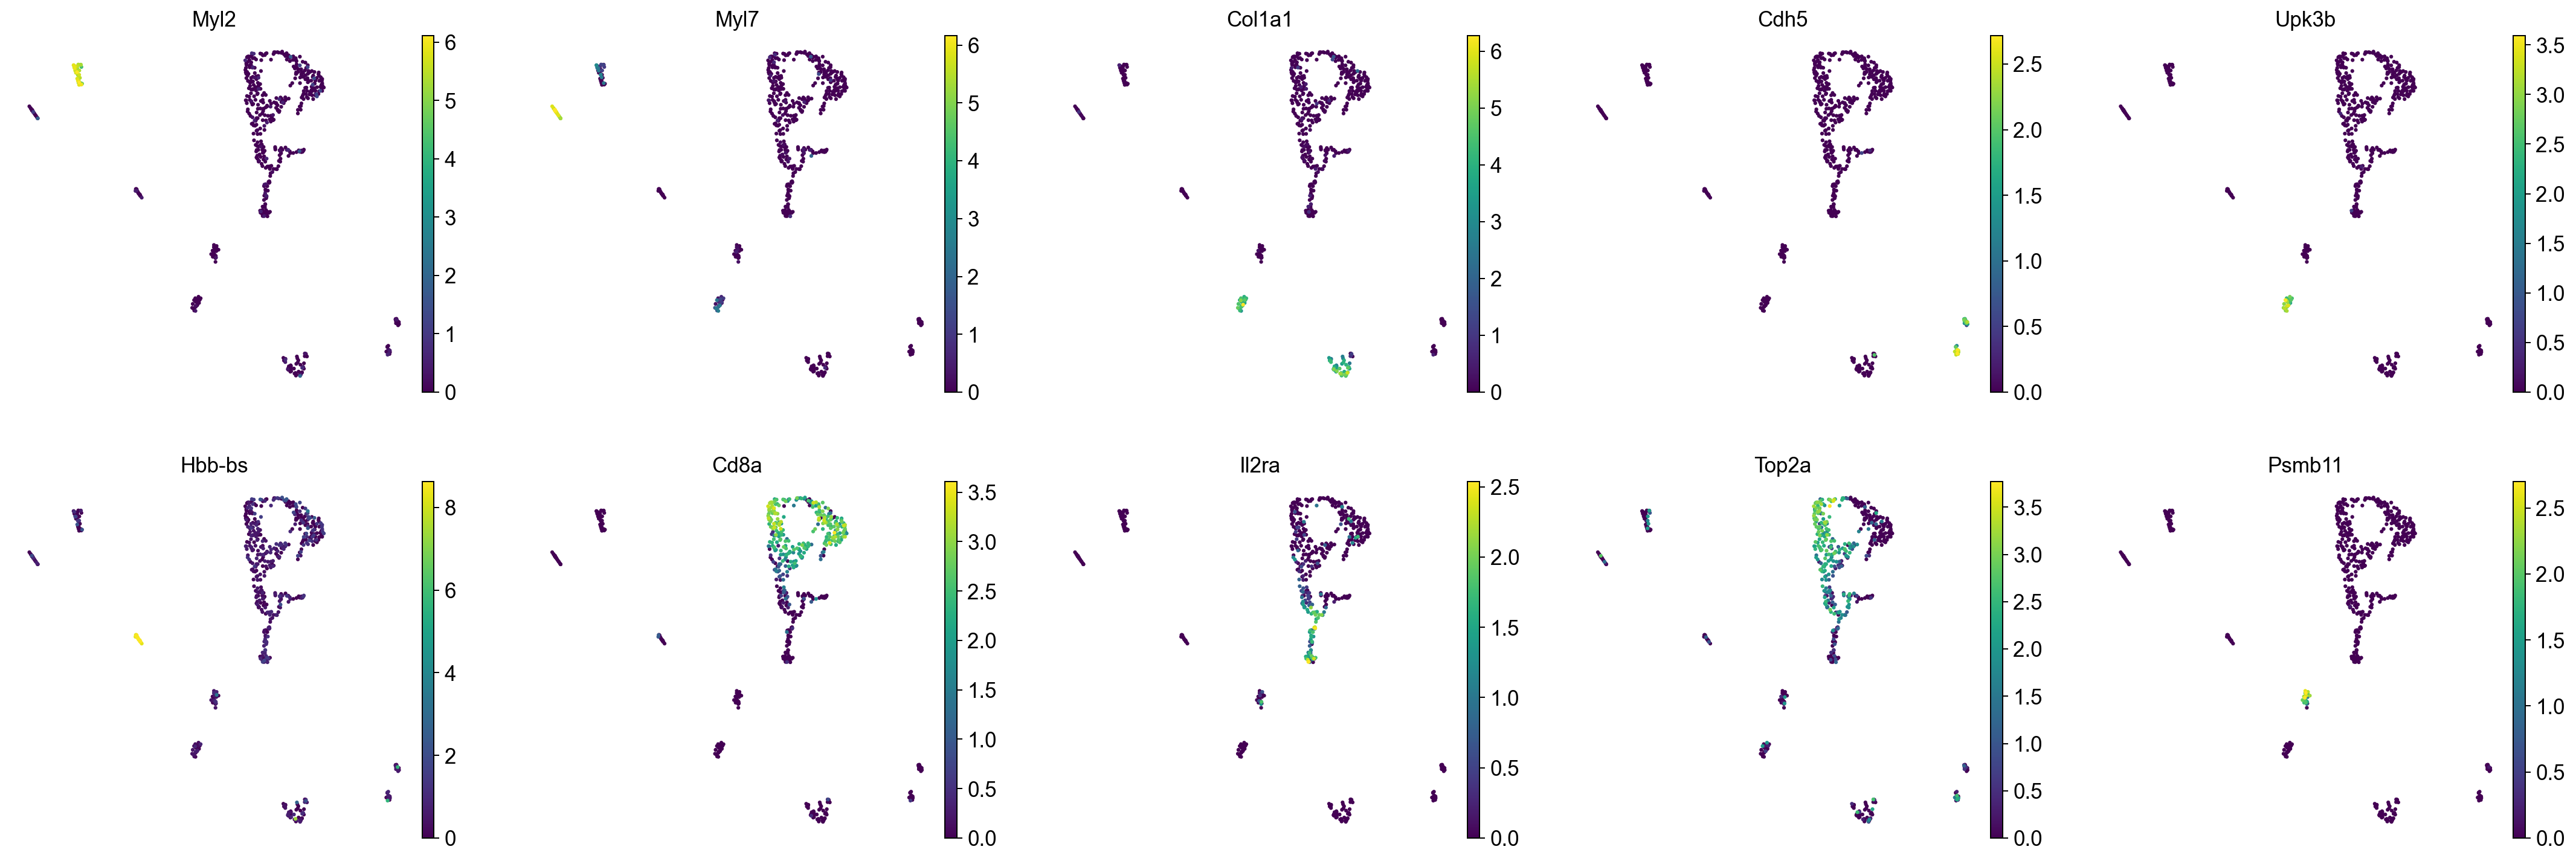

In [24]:
sc.pl.umap(heart, color=["Myl2", "Myl7", "Col1a1", "Cdh5", "Upk3b", "Hbb-bs",
                         "Cd8a", "Il2ra", "Top2a", "Psmb11"], ncols=5, size=25, use_raw=False)

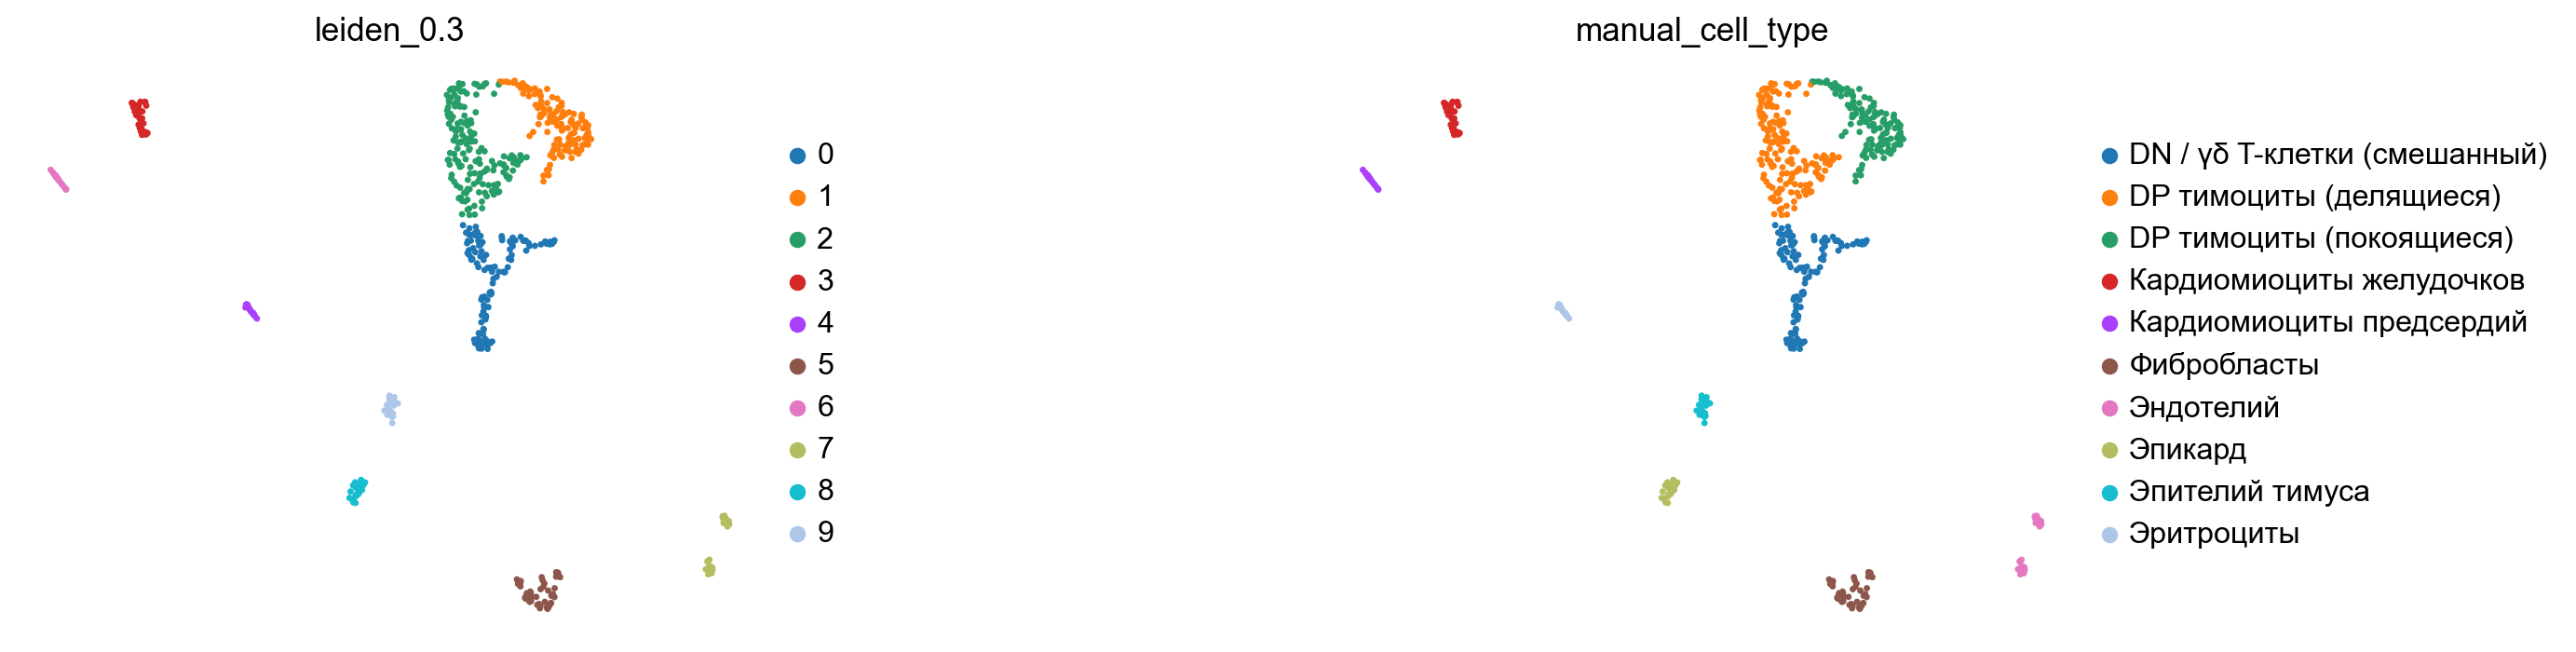

In [25]:
manual_annotations = {
    "0": "DN / γδ T-клетки (смешанный)",
    "1": "DP тимоциты (покоящиеся)",
    "2": "DP тимоциты (делящиеся)",
    "3": "Кардиомиоциты желудочков",
    "4": "Эритроциты",
    "5": "Фибробласты",
    "6": "Кардиомиоциты предсердий",
    "7": "Эндотелий",
    "8": "Эпикард",
    "9": "Эпителий тимуса",
}
heart.obs["manual_cell_type"] = pd.Categorical(
    heart.obs[CLUSTER_KEY].astype(str).map(manual_annotations).fillna("Unknown"))

sc.pl.umap(heart, color=[CLUSTER_KEY, "manual_cell_type"], ncols=2, size=30, wspace=0.6,
           legend_loc="right margin")

### Таблица ручной аннотации (`leiden_0.3`)

| Кластер | Клеток | Предполагаемый тип | Маркерные гены | Обоснование |
|---|---|---|---|---|
| 0 | 124 | DN / γδ T-клетки (смешанный) | `Nkg7`, `Tcrg-C2`, `Il2ra`, `Trdc`, `Cd3e` | T-клетки (`Cd3e`) без `Cd4`/`Cd8a`; одновременно γδ-TCR и `Il2ra` (CD25) — смесь, разобрана в задании 6 |
| 1 | 130 | DP тимоциты (покоящиеся) | `Cd8b1`, `Cd8a`, `Cd4`, `Satb1`, `Lck`, `Rag1` | CD4⁺CD8⁺ с `Rag1` — незрелые тимоциты; `Top2a` низкий |
| 2 | 167 | DP тимоциты (делящиеся) | `Top2a`, `Mki67`, `Birc5`, `Pclaf`, `Cd8a` | те же DP-маркеры + программа деления |
| 3 | 35 | Кардиомиоциты желудочков | `Mb`, `Pln`, `Myoz2`, `Tnnt2`, `Myl2`, `Myl3` | саркомерные гены + желудочковые лёгкие цепи миозина |
| 4 | 20 | Эритроциты | `Alas2`, `Gypa`, `Hbb-bs` | синтез гема, гликофорин A, гемоглобины |
| 5 | 52 | Фибробласты | `Postn`, `Col1a2`, `Col6a1-3`, `Pdgfra`, `Aspn` | коллагены и PDGFRα |
| 6 | 21 | Кардиомиоциты предсердий | `Sln`, `Myl7`, `Nppa`, `Mybphl` | `Tnnt2` + предсердные маркеры |
| 7 | 29 | Эндотелий | `Cdh5`, `Tie1`, `Sox18`, `Emcn`, `Pecam1` | VE-кадгерин, Tie1, эндомуцин |
| 8 | 24 | Эпикард | `Upk3b`, `Msln`, `Lrrn4`, `Muc16`, `Wt1` | мезотелиальная программа и `Wt1` |
| 9 | 23 | Эпителий тимуса | `Trp63`, `Psmb11`, `Krt8`, `Foxn1` | кератины эпителия, тимопротеасома кортикального эпителия (`Psmb11`), `Foxn1` — главный регулятор эпителия тимуса |

Кластеры 0, 1, 2 и 9 к сердцу не относятся: это клетки **тимуса**. У мыши тимус прилегает к основанию сердца и, вероятно, попал в образец при выделении. Названия типов предположительные: они основаны на маркерах, а не на функциональной проверке.

## Задание 5. Автоматическая аннотация (CellTypist)

**Ограничение.** Готовых моделей CellTypist для **сердца мыши** нет: модели для сердца и иммунных клеток обучены на данных **человека**. Поэтому:

1. берём две человеческие модели: `Immune_All_Low.pkl` (иммунные клетки, включая тимоциты) и `Healthy_Adult_Heart.pkl` (Heart Cell Atlas, взрослое сердце человека);
2. переводим их на гены мыши встроенной функцией `model.convert()`. Она сопоставляет гены через таблицу ортологов Ensembl, которая поставляется вместе с CellTypist; используются только ортологи 1:1;
3. запускаем `celltypist.annotate` на лог-нормализованной матрице (`normalize_total` до 10⁴ + `log1p`), то есть в том формате, который ожидает CellTypist.

Модели скачиваются вручную с https://www.celltypist.org/models и кладутся в `data/celltypist_models/`.

In [26]:
import celltypist
from celltypist import models

MODEL_DIR = DATA_DIR / "celltypist_models"
CT_MODELS = {"ct_immune": "Immune_All_Low.pkl", "ct_heart": "Healthy_Adult_Heart.pkl"}

for key, fname in CT_MODELS.items():
    model = models.Model.load(str(MODEL_DIR / fname))
    n_before = len(model.features)
    model.convert()                                   # человек → мышь по ортологам 1:1
    print(f"{fname}: генов в модели {n_before} → {len(model.features)} после перевода; "
          f"из них есть в данных {np.isin(model.features, heart.var_names).sum()}")
    pred = celltypist.annotate(heart, model=model, majority_voting=False)
    heart.obs[key] = pd.Categorical(pred.predicted_labels["predicted_labels"].astype(str))
    heart.obs[key + "_conf"] = pred.probability_matrix.max(axis=1).astype(float)
    # Для читаемых UMAP: редкие метки (< 5 клеток) объединяем в «другие»
    counts = heart.obs[key].value_counts()
    rare = counts.index[counts < 5]
    heart.obs[key + "_main"] = pd.Categorical(
        heart.obs[key].astype(str).where(~heart.obs[key].isin(rare), "другие (<5 клеток)"))

c:\Users\Lenovo Ideapad 5\AppData\Local\Programs\Python\Python311\Lib\site-packages\celltypist\classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv
🔎 No available models. Downloading...
📜 Retrieving model list from server https://celltypist.cog.sanger.ac.uk/models/models.json
📚 Total models in list: 61
📂 Storing models in C:\Users\Lenovo Ideapad 5\.celltypist\data\models
💾 Downloading model [1/61]: Immune_All_Low.pkl
💾 Downloading model [2/61]: Immune_All_High.pkl
💾 Downloading model [3/61]: Adult_COVID19_PBMC.pkl
💾 Downloading model [4/61]: Adult_CynomolgusMacaque_Hippocampus.pkl
💾 Downloading model [5/61]: Adult_Human_MTG.pkl
💾 Downloading model [6/61]: Adult_Human_PancreaticIslet.pkl
💾 Downloading model [7/61]: Adult_Human_PrefrontalCortex.pkl
💾 Downloading model [8/61]: Adult_Human_Skin.pkl
💾 Downloading model [9/61]: Adult_Human_Vascular.pkl
💾 Downloading model [10/61]: Adult_Mouse_

Immune_All_Low.pkl: генов в модели 6639 → 4760 после перевода; из них есть в данных 4321


🧬 4321 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
🧬 Number of genes in the original model: 3874
✅ Conversion done! Number of genes in the converted model: 3156
🔬 Input data has 625 cells and 16619 genes
🔗 Matching reference genes in the model


Healthy_Adult_Heart.pkl: генов в модели 3874 → 3156 после перевода; из них есть в данных 2864


🧬 2864 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


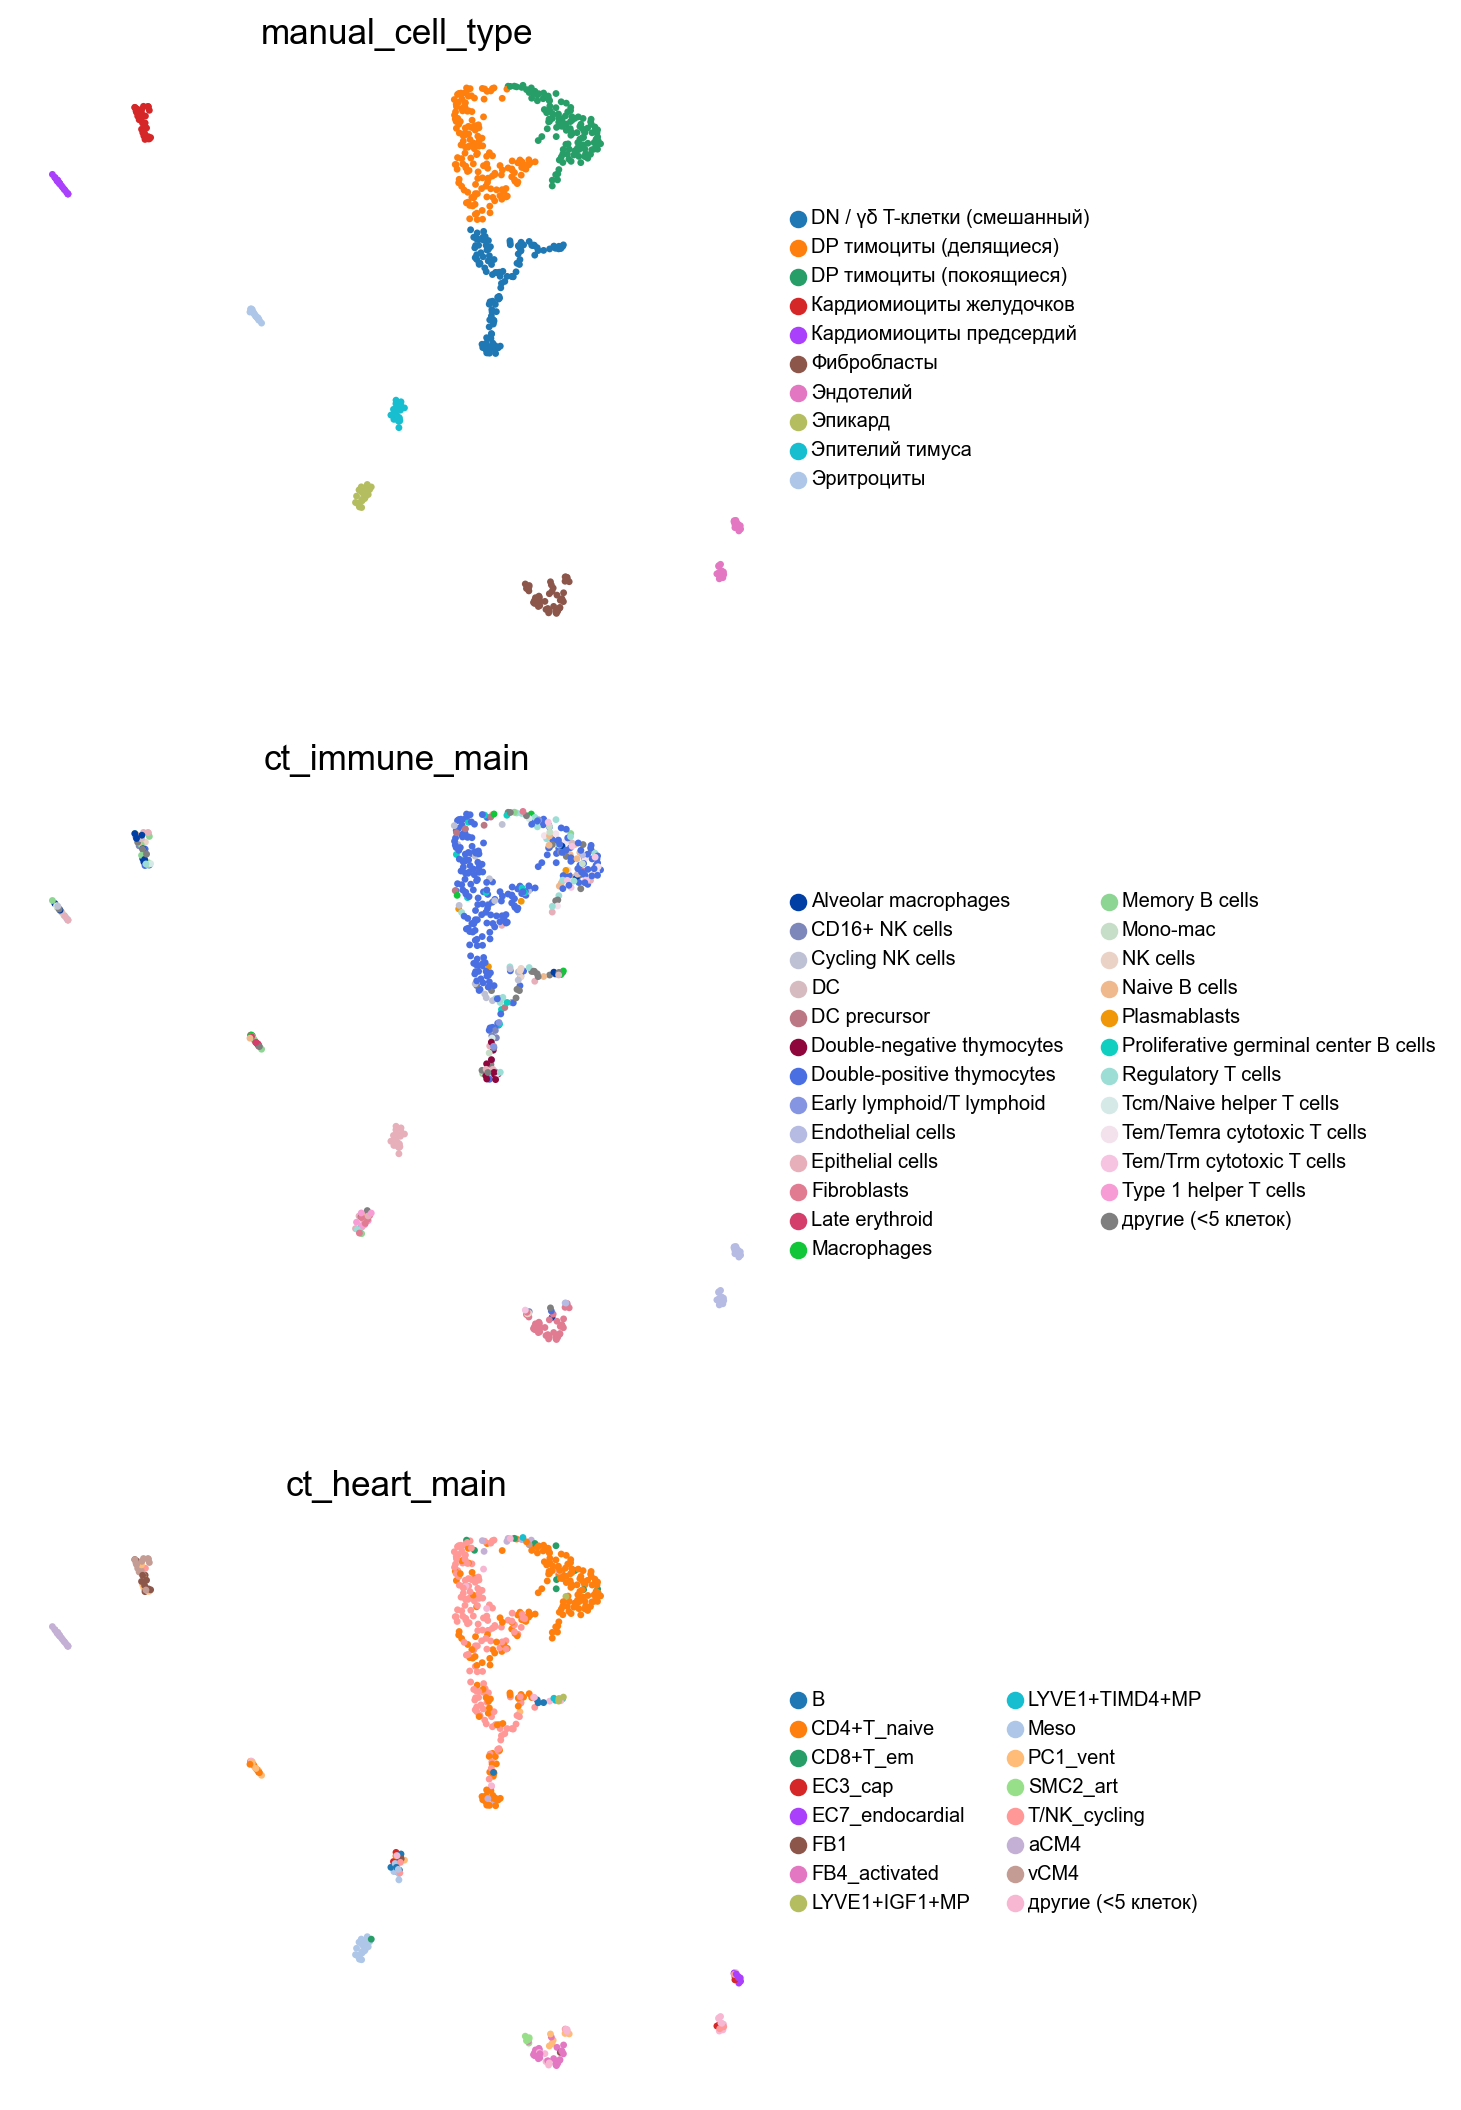

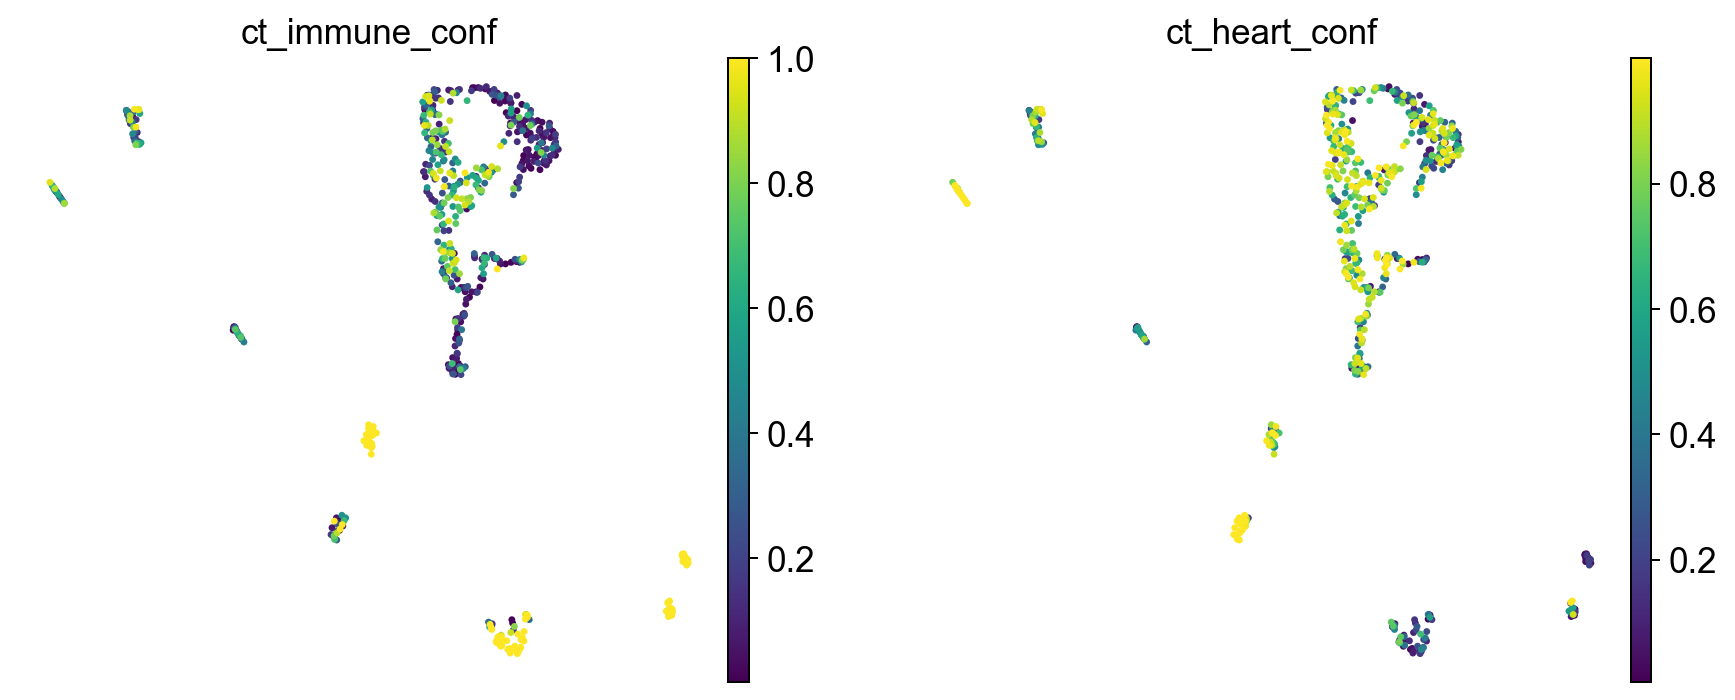

In [27]:
sc.pl.umap(heart, color=["manual_cell_type", "ct_immune_main", "ct_heart_main"], ncols=1, size=30,
           legend_loc="right margin", legend_fontsize=8)
sc.pl.umap(heart, color=["ct_immune_conf", "ct_heart_conf"], ncols=2, size=30, cmap="viridis")

In [28]:
# Таблицы сопряжённости: ручная аннотация × автоматическая
# (строки — метки CellTypist, столбцы — ручная аннотация; пустая ячейка = 0)
pd.set_option("display.max_rows", 100)
for key in CT_MODELS:
    tab = pd.crosstab(heart.obs[key], heart.obs["manual_cell_type"])
    display(tab.replace(0, "").style.set_caption(f"{CT_MODELS[key]}: CellTypist × ручная аннотация"))

manual_cell_type,DN / γδ T-клетки (смешанный),DP тимоциты (делящиеся),DP тимоциты (покоящиеся),Кардиомиоциты желудочков,Кардиомиоциты предсердий,Фибробласты,Эндотелий,Эпикард,Эпителий тимуса,Эритроциты
ct_immune,,,,,,,,,,
Age-associated B cells,1,,,,,,,,,
Alveolar macrophages,2,,2,8,2,1,,,,
B cells,,,1,,,,,,,
CD16+ NK cells,6,,2,1,,1,,,,
CD8a/a,,,1,,,,,,,
CD8a/b(entry),,,2,,,,,,,
Cycling NK cells,9,9,,,1,,,,,
DC,2,,2,1,2,,,,,
DC precursor,2,6,,,,,,,,


manual_cell_type,DN / γδ T-клетки (смешанный),DP тимоциты (делящиеся),DP тимоциты (покоящиеся),Кардиомиоциты желудочков,Кардиомиоциты предсердий,Фибробласты,Эндотелий,Эпикард,Эпителий тимуса,Эритроциты
ct_heart,,,,,,,,,,
B,4,,,,,,,,6,
CD16+Mo,2,,,,,,,,,1
CD4+T_naive,47,48,113,,,,,,1,5
CD4+T_reg,1,2,1,,,,,,,
CD8+T_em,,2,8,,,,,1,,
CD8+T_trans,2,,,,,,,,1,
EC10_CMC-like,,,,,,,2,,,
EC1_cap,,,,,,,4,,,
EC3_cap,,,,,,,4,,3,


In [29]:
# То же по кластерам Leiden: основная метка CellTypist в каждом кластере и её доля
summary = {}
for key in CT_MODELS:
    tab = pd.crosstab(heart.obs[CLUSTER_KEY], heart.obs[key], normalize="index")
    summary[key] = (tab.idxmax(axis=1).astype(str) + "  (" +
                    (tab.max(axis=1) * 100).round(0).astype(int).astype(str) + "%)")
pd.DataFrame(summary).assign(manual=pd.Series(manual_annotations))

,ct_immune,ct_heart,manual
leiden_0.3,,,
0,Double-positive thymocytes (31%),T/NK_cycling (43%),DN / γδ T-клетки (смешанный)
1,Double-positive thymocytes (44%),CD4+T_naive (88%),DP тимоциты (покоящиеся)
2,Double-positive thymocytes (82%),T/NK_cycling (67%),DP тимоциты (делящиеся)
3,Alveolar macrophages (23%),vCM4 (49%),Кардиомиоциты желудочков
4,Late erythroid (50%),PC1_vent (65%),Эритроциты
5,Fibroblasts (83%),FB4_activated (52%),Фибробласты
6,Memory B cells (24%),aCM4 (100%),Кардиомиоциты предсердий
7,Endothelial cells (100%),EC7_endocardial (34%),Эндотелий
8,Fibroblasts (25%),Meso (96%),Эпикард


**Выводы.** 

- **Совпадения:**
  - *Immune_All_Low*: фибробласты (83 % → `Fibroblasts`, уверенность 1.0), эндотелий (100 % → `Endothelial cells`), эпителий тимуса (100 % → `Epithelial cells`), делящиеся DP-тимоциты (82 % → `Double-positive thymocytes`), эритроциты (`Late erythroid`, 50 %);
  - *Healthy_Adult_Heart*: кардиомиоциты предсердий (100 % → `aCM4`), эпикард (96 % → `Meso`, мезотелий), желудочковые КМ (49 % → `vCM4`), фибробласты (52 % → `FB4_activated`, плюс `SMC`/перициты), эндотелий почти целиком в классах `EC*` (из них 10 клеток `EC7_endocardial`).
- **Макрофаги, найденные субкластеризацией** (задание 6), подтверждаются обеими моделями: в 11 из 16 клеток *Immune_All_Low* ставит миелоидную метку (`Kupffer cells`, `Macrophages`, `Alveolar macrophages`, DC), *Healthy_Adult_Heart* — `LYVE1⁺ MP` или `CD16⁺Mo`.
- **Расхождения:**
  1. Модель **сердца** не знает тимоцитов и называет их ближайшими T-классами взрослого сердца: `CD4+T_naive`, `T/NK_cycling`. Эпителий тимуса она относит к `Meso`/`B`, эритроциты — к `PC1_vent` (перициты), потому что в атласе взрослого сердца нет ни тимуса, ни эритроцитов.
  2. Модель **иммунных клеток** ставит клеткам сердца случайные иммунные метки с низкой уверенностью: кардиомиоциты → `Alveolar macrophages`, `Memory B cells`.
  3. Покоящиеся DP-тимоциты лишь в 44 % случаев получили `Double-positive thymocytes`, остальные разошлись по `Regulatory T`, `Tem` и `Naive B` (медианная уверенность 0.07).
- **Причины расхождений:**
  - **вид**: модели человеческие; после перевода по ортологам 1:1 используется 4321 и 2864 гена вместо 6639 и 3874;
  - **стадия**: эмбрион E18 против взрослых референсов;
  - **ткань**: тимус отсутствует в атласе сердца;
  - CellTypist — классификатор с **закрытым набором классов**: он всегда выбирает один из известных ему типов, даже если клетка ни на один не похожа;
  - малые размеры популяций.
- **Что обоснованнее.** Для этих данных — **ручная аннотация**. Она опирается на маркеры, проверенные в самих данных (dotplot, UMAP), и учитывает, что часть клеток из тимуса. CellTypist полезен как независимая проверка и как подсказка для мелких групп (например, макрофагов), если смотреть только на метки модели, подходящей к ткани, и учитывать уверенность.

## Задание 6. Субкластеризация

Выбираем **кластер 0** (124 клетки). В нём одновременно высоко экспрессируются `Nkg7`, `Tcrg-C`, `Il2ra` и `Plac8`, а в ручной аннотации он остался «смешанным». Значит, внутри, вероятно, несколько подтипов.

Для подмножества заново проходим весь путь начиная с **сырых counts**: HVG, отобранные на всех клетках, отражают различия между крупными популяциями (сердце vs T-клетки), а нам нужны гены, которые варьируют *внутри* кластера.

{'0': 24, '1': 34, '2': 18, '3': 23, '4': 16, '5': 9}


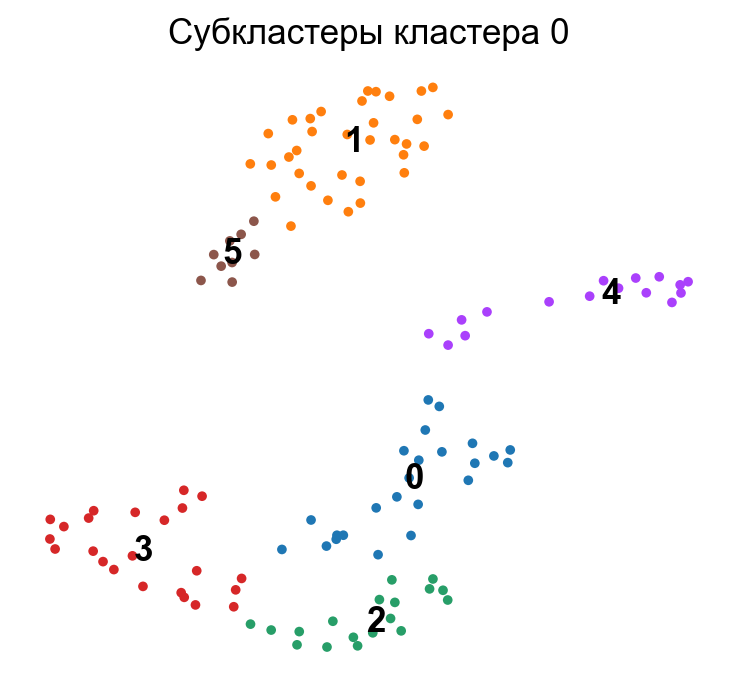

In [30]:
SUB_CLUSTER = "0"
sub = heart[heart.obs[CLUSTER_KEY] == SUB_CLUSTER].copy()
sub.X = sub.layers["counts"].copy()                       # начинаем с сырых counts
sub.uns.pop("log1p", None)                                # метка «уже логарифмировано» от исходного объекта
sc.pp.normalize_total(sub, target_sum=1e4)
sc.pp.log1p(sub)
sc.pp.highly_variable_genes(sub, layer="counts", flavor="seurat_v3", n_top_genes=1000)  # меньше клеток → меньше HVG
sc.tl.pca(sub, n_comps=30, mask_var="highly_variable", random_state=SEED)
sc.pp.neighbors(sub, n_neighbors=10, n_pcs=10, random_state=SEED)                     # маленькая выборка → меньше соседей
sc.tl.umap(sub, min_dist=0.3, random_state=SEED)
sc.tl.leiden(sub, resolution=0.5, key_added="subcluster", flavor="igraph",
             n_iterations=2, directed=False, random_state=0)
print(sub.obs["subcluster"].value_counts().sort_index().to_dict())
sc.pl.umap(sub, color="subcluster", legend_loc="on data", size=60, title=f"Субкластеры кластера {SUB_CLUSTER}")

In [31]:
sc.tl.rank_genes_groups(sub, groupby="subcluster", method="wilcoxon", use_raw=False,
                        tie_correct=True, pts=True, key_added="wilcoxon")
pd.DataFrame({cl: sc.get.rank_genes_groups_df(sub, group=cl, key="wilcoxon").head(10)["names"].values
              for cl in sub.obs["subcluster"].cat.categories})

,0,1,2,3,4,5
0,Tmsb10,Gm4632,Rrm2,Adgrg1,Ctss,P4ha3
1,Cd2,Hdac4,Cenpi,Cd93,App,Zan
2,Il2rb,Tm6sf1,Npm1,4930519L02Rik,Cfp,Arhgap42
3,Ms4a4b,Tshz2,Mybl2,Gm19590,Aif1,Dusp9
4,Gimap4,Dtx1,Ybx1,Pbk,C1qc,Cracr2b
5,Pfn1,Spib,Gsdme,Pimreg,Ctsh,Rnf39
6,Osbpl3,Arl5c,Cad,Stmn1,Cybb,Podxl
7,B630019A10Rik,mt-Co1,Fbxo5,Ankrd27,Cd83,Tox3
8,Cxcr6,Srsf5,Eif5a,Kif15,Hmox1,Gulo
9,S100a6,mt-Co3,Ncl,Tuba4a,C1qa,Spock2


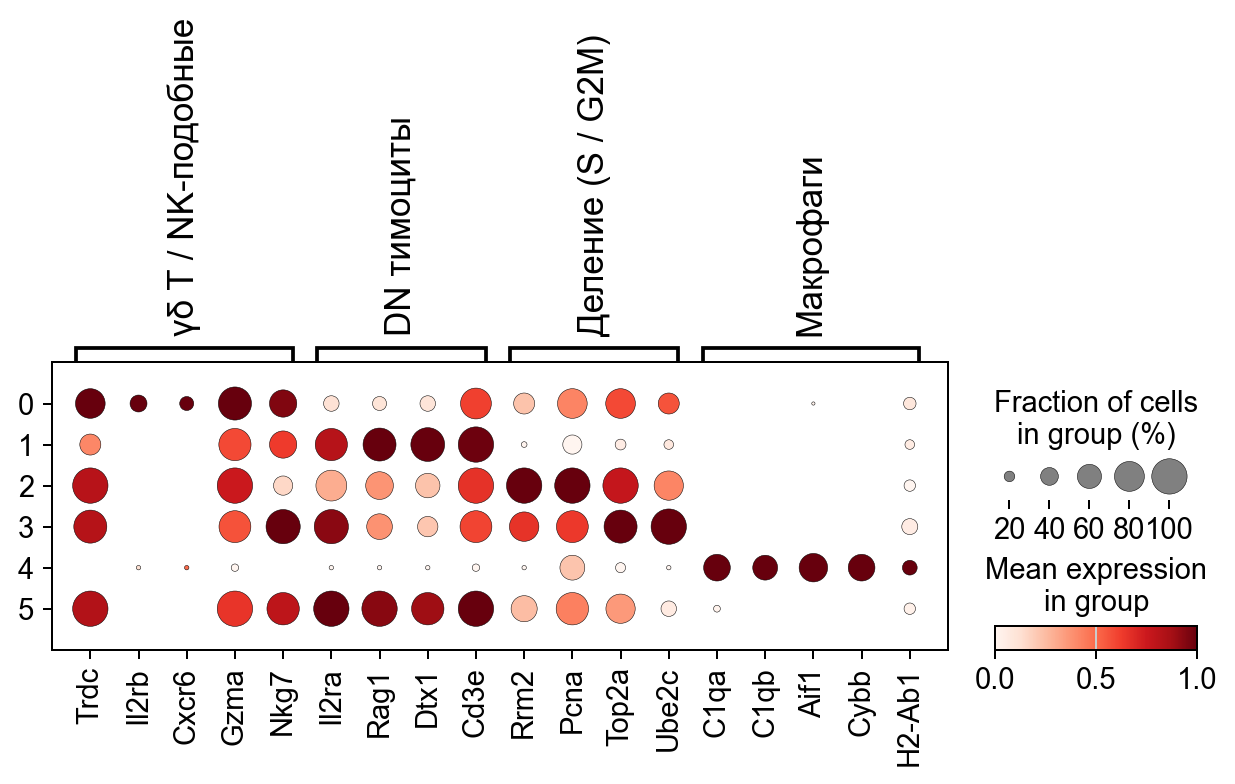

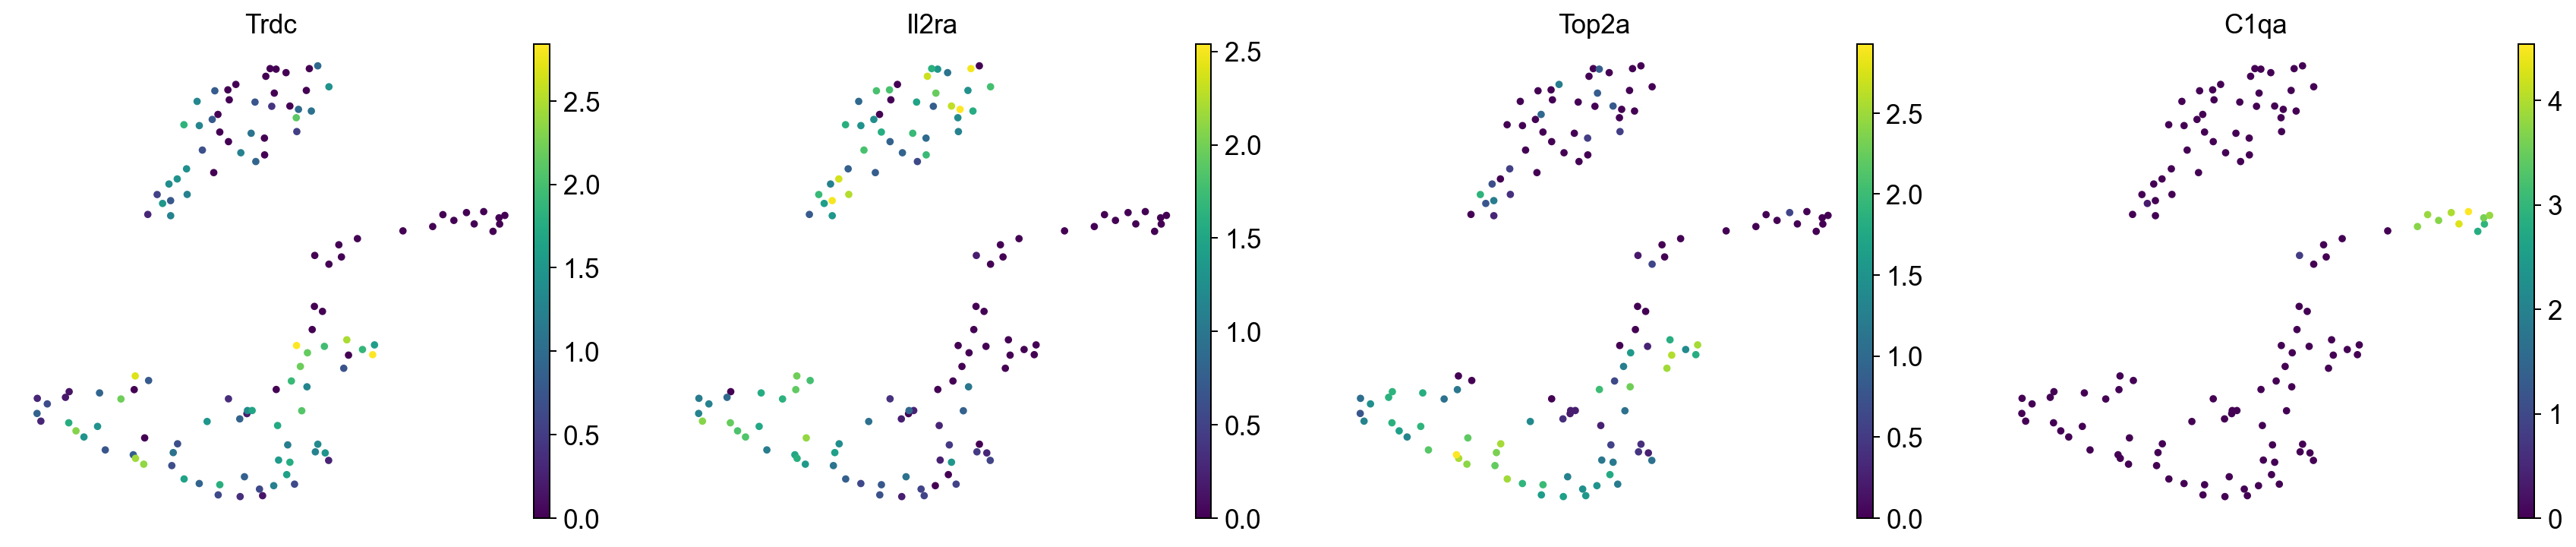

In [32]:
SUB_MARKERS = {
    "γδ T / NK-подобные": ["Trdc", "Il2rb", "Cxcr6", "Gzma", "Nkg7"],
    "DN тимоциты": ["Il2ra", "Rag1", "Dtx1", "Cd3e"],
    "Деление (S / G2M)": ["Rrm2", "Pcna", "Top2a", "Ube2c"],
    "Макрофаги": ["C1qa", "C1qb", "Aif1", "Cybb", "H2-Ab1"],
}
sc.pl.dotplot(sub, SUB_MARKERS, groupby="subcluster", standard_scale="var", use_raw=False)
sc.pl.umap(sub, color=["Trdc", "Il2ra", "Top2a", "C1qa"], ncols=4, size=60)

... storing 'sub_cell_type' as categorical


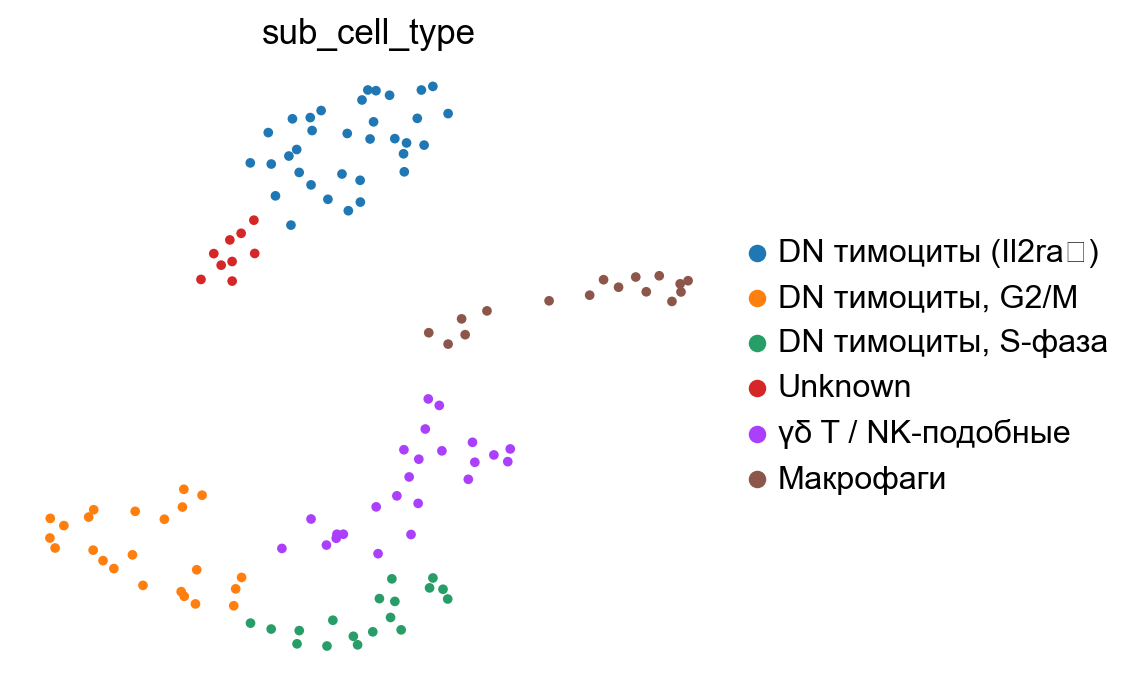

In [33]:
sub_annotations = {
    "0": "γδ T / NK-подобные",
    "1": "DN тимоциты (Il2ra⁺)",
    "2": "DN тимоциты, S-фаза",
    "3": "DN тимоциты, G2/M",
    "4": "Макрофаги",
    "5": "Unknown",
}
sub.obs["sub_cell_type"] = sub.obs["subcluster"].astype(str).map(sub_annotations)

# Переносим уточнённые метки в общий объект
heart.obs["refined_cell_type"] = heart.obs["manual_cell_type"].astype(str)
heart.obs.loc[sub.obs_names, "refined_cell_type"] = sub.obs["sub_cell_type"]
heart.obs["refined_cell_type"] = pd.Categorical(heart.obs["refined_cell_type"])
sc.pl.umap(sub, color="sub_cell_type", size=60, legend_loc="right margin")

**Выводы.** 

- **Разделение удалось.** Из 124 клеток кластера 0 выделились 6 субкластеров, и 5 из них интерпретируются:
  - **γδ T / NK-подобные** (24): `Trdc`, `Il2rb`, `Cxcr6`, `Cd2`, `Gzma`, `Nkg7`;
  - **DN-тимоциты** (34): `Il2ra` (CD25) + `Rag1` + `Dtx1` (мишень Notch) без `Cd4`/`Cd8`. Это картина ранних CD4⁻CD8⁻ стадий (DN2–DN3), когда идёт перестройка β-цепи TCR;
  - **DN-тимоциты в S-фазе** (18): `Rrm2`, `Mybl2`, `Cenpi`;
  - **DN-тимоциты в G2/M** (23): `Pbk`, `Ube2c`, `Stmn1`, `Kif15`;
  - **макрофаги** (16): `C1qa/b/c`, `Aif1`, `Cybb`, `Ctss`, `H2-Ab1`. Это вообще не T-клетки;
  - 9 клеток (`Tox3`, `Ncam1`, `Podxl`) уверенно не определены — `Unknown`. Это могут быть дублеты или редкий тип.
- **Почему не было видно при общей кластеризации.**
  - Макрофагов всего 16 из 625 (2.5 %). Их сигнал почти не влияет на главные компоненты, рассчитанные по всем клеткам.
  - При `n_neighbors = 15` такая маленькая группа частично связана в графе с соседними T-клетками.
  - При `resolution = 0.3` модулярность выгоднее объединять мелкие группы с соседями.
  - Глобальные HVG в основном описывают крупные различия («сердце vs кровь vs тимус»).
  На подмножестве HVG пересчитаны внутри кластера, и PCA описывает уже именно внутрикластерные различия, поэтому подтипы и состояния становятся видны.

## Задание 7. Генные программы

| Программа | Гены | Источник |
|---|---|---|
| Пролиферация | `Mki67`, `Top2a`, `Pcna`, `Tyms` | пример из задания; гены S- и G2/M-фаз из Tirosh et al., 2016 |
| Презентация антигена через MHC II | `H2-Aa`, `H2-Ab1`, `H2-Eb1`, `Cd74`, `H2-DMa`, `H2-DMb1` | GO:0019886 *antigen processing and presentation of exogenous peptide antigen via MHC class II* |
| Внеклеточный матрикс | `Col1a1`, `Col1a2`, `Col3a1`, `Dcn`, `Lum`, `Postn` | MSigDB `NABA_CORE_MATRISOME` (коллагены, протеогликаны, гликопротеины ECM) |

Программы выбраны так, чтобы проверять разные стороны аннотации: состояние клеток (деление), функцию иммунных и эпителиальных клеток (MHC II) и функцию стромы (ECM).

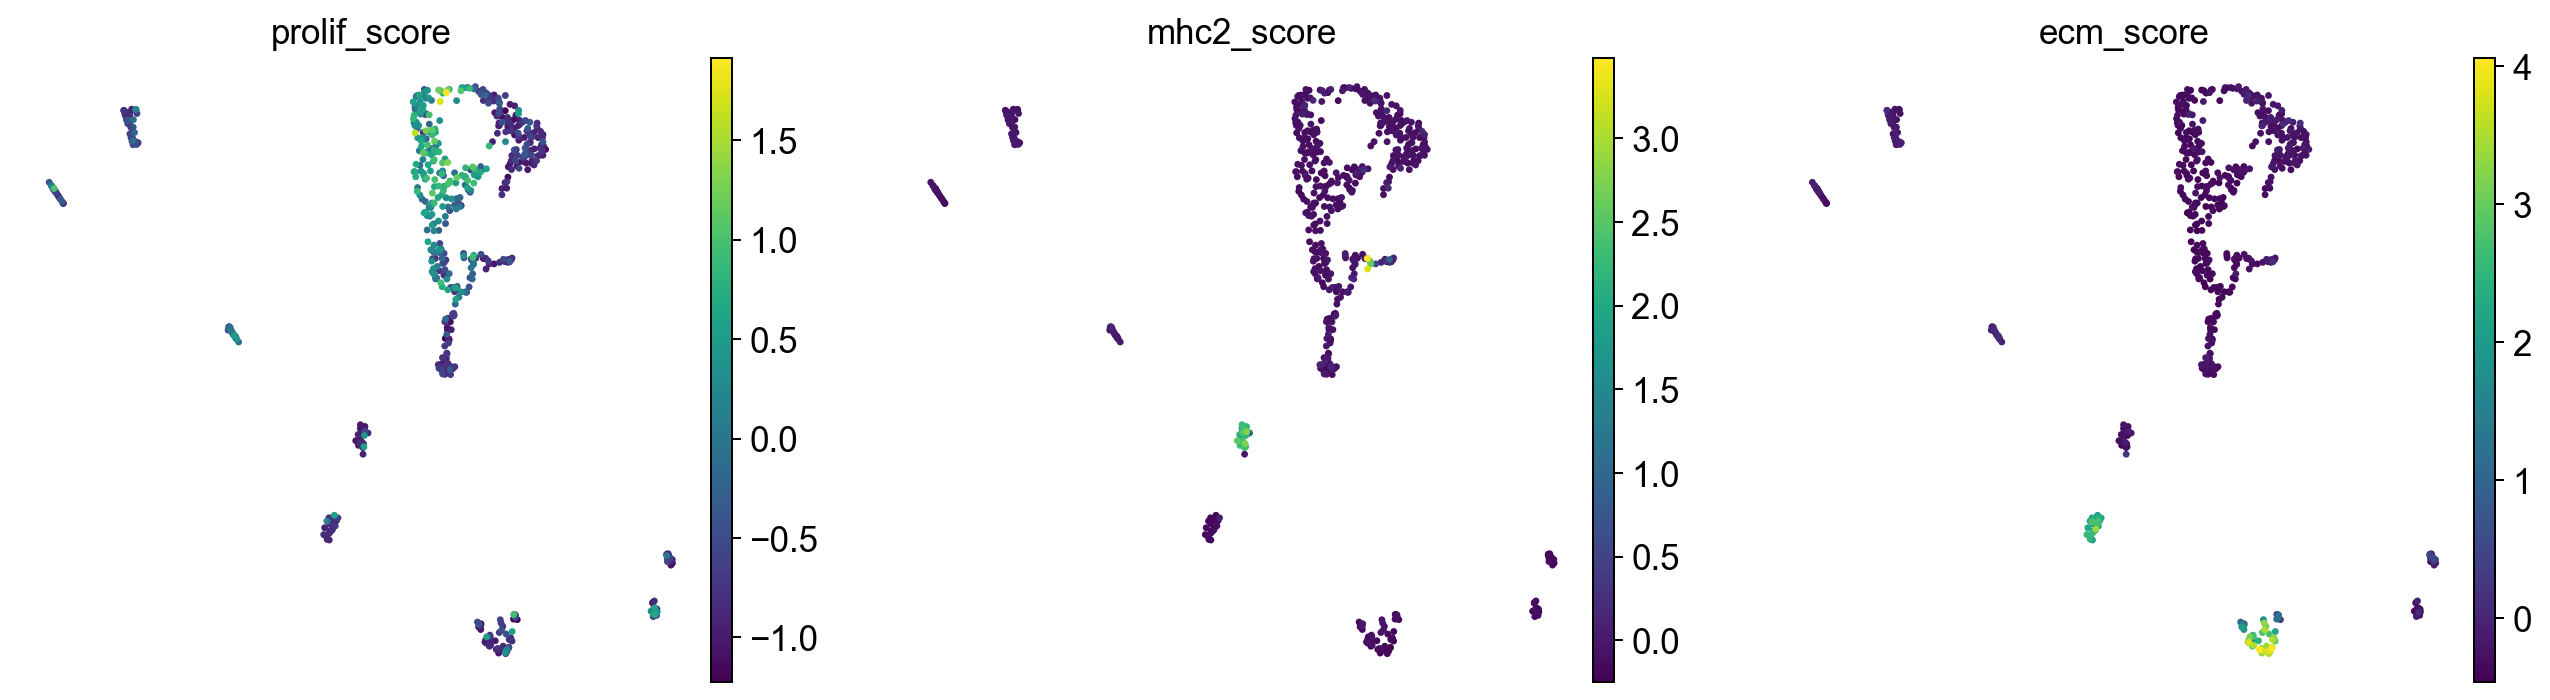

In [34]:
PROGRAMS = {
    "prolif_score": ["Mki67", "Top2a", "Pcna", "Tyms"],
    "mhc2_score": ["H2-Aa", "H2-Ab1", "H2-Eb1", "Cd74", "H2-DMa", "H2-DMb1"],
    "ecm_score": ["Col1a1", "Col1a2", "Col3a1", "Dcn", "Lum", "Postn"],
}
for name, genes in PROGRAMS.items():
    genes = [g for g in genes if g in heart.var_names]
    sc.tl.score_genes(heart, gene_list=genes, score_name=name, use_raw=False, random_state=SEED)

sc.pl.umap(heart, color=list(PROGRAMS), ncols=3, size=30, cmap="viridis")

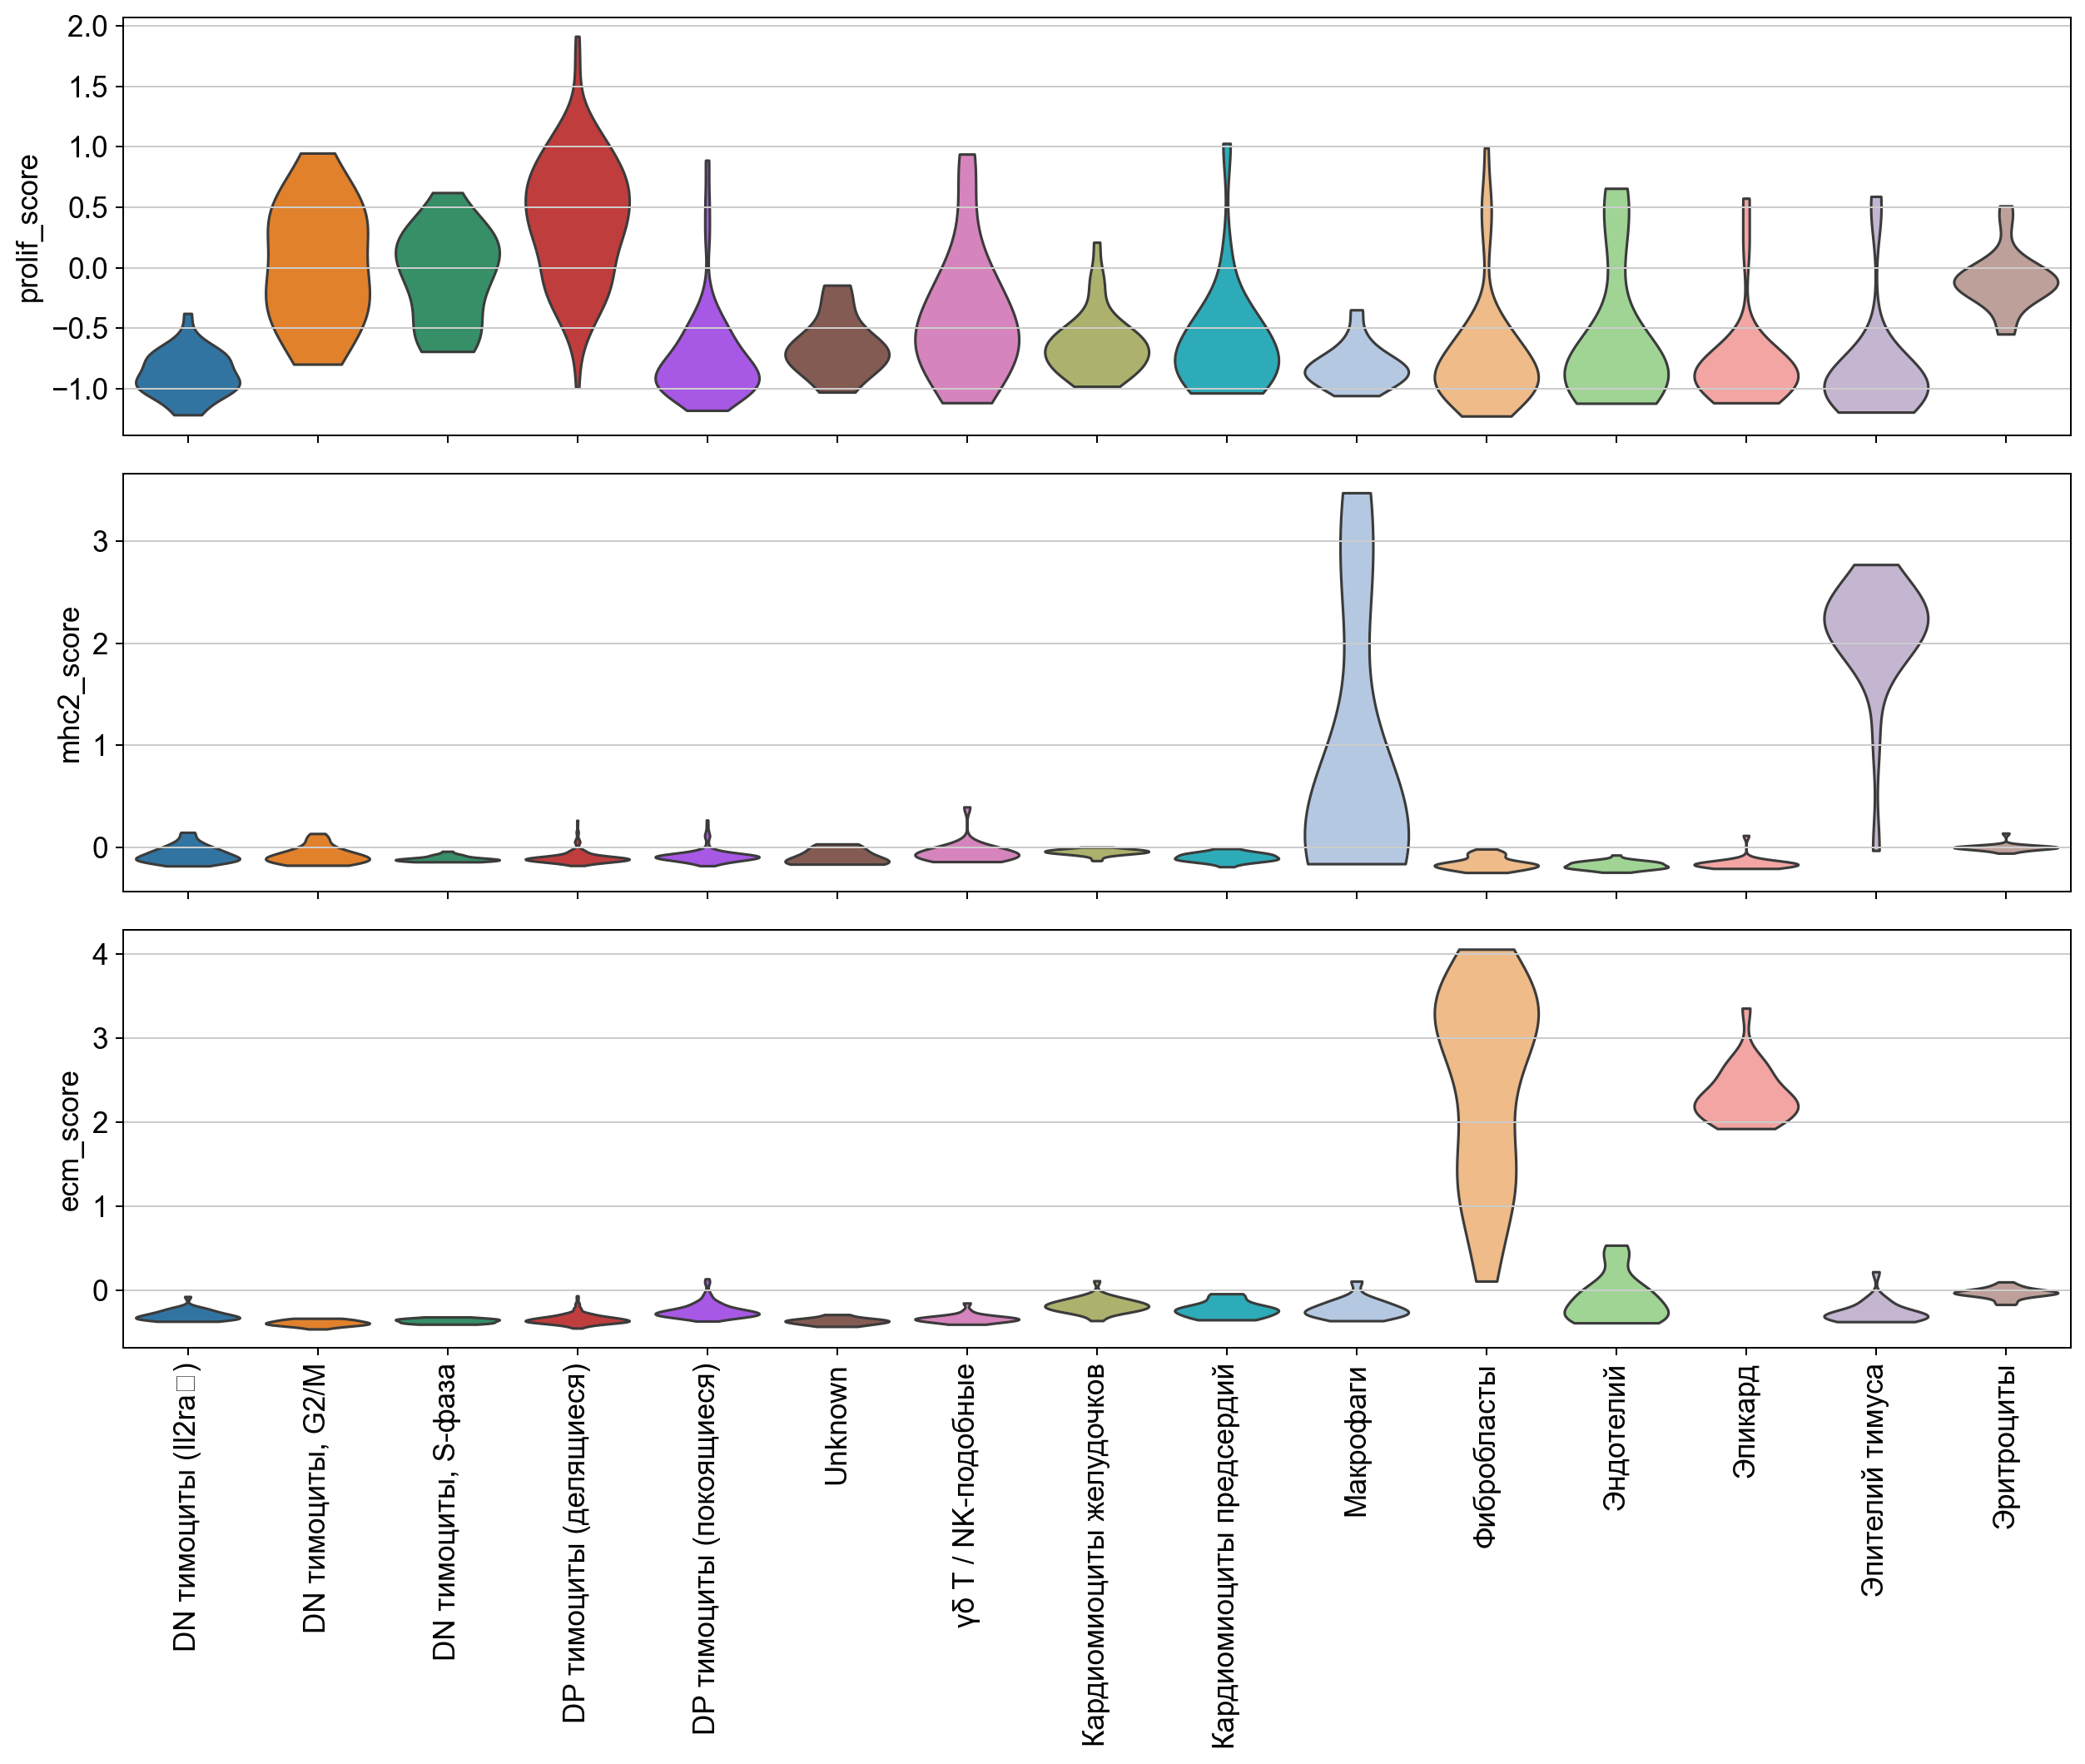

In [35]:
fig, axes = plt.subplots(len(PROGRAMS), 1, figsize=(14, 4 * len(PROGRAMS)))
for ax, name in zip(axes, PROGRAMS):
    sc.pl.violin(heart, name, groupby="refined_cell_type", rotation=90, stripplot=False, ax=ax, show=False)
    ax.tick_params(axis="x", labelbottom=(ax is axes[-1]))
plt.tight_layout(); plt.show()

In [36]:
# Средний score по типам клеток (по уточнённой аннотации); жирным — максимум
score_table = heart.obs.groupby("refined_cell_type", observed=True)[list(PROGRAMS)].mean().round(2)
score_table.style.highlight_max(axis=0, props="font-weight:bold; background-color:#ffe08a").format("{:.2f}")

,prolif_score,mhc2_score,ecm_score
refined_cell_type,,,
DN тимоциты (Il2ra⁺),-0.88,-0.07,-0.29
"DN тимоциты, G2/M",0.03,-0.07,-0.39
"DN тимоциты, S-фаза",-0.07,-0.11,-0.36
DP тимоциты (делящиеся),0.40,-0.10,-0.34
DP тимоциты (покоящиеся),-0.74,-0.08,-0.24
Unknown,-0.64,-0.09,-0.37
γδ T / NK-подобные,-0.41,-0.05,-0.33
Кардиомиоциты желудочков,-0.63,-0.05,-0.18
Кардиомиоциты предсердий,-0.60,-0.10,-0.22


**Выводы.** 

- **Пролиферация** выше всего в делящихся DP-тимоцитах (средний score 0.40) и DN-тимоцитах в G2/M (0.03), низкая — в покоящихся DP (−0.72) и во всех клетках сердца (−0.6…−0.8). Программа подтверждает деление DP-тимоцитов на «делящиеся» и «покоящиеся» (кластеры 1 и 2) и показывает, что субкластеры DN в S- и G2/M-фазе — состояния одной популяции, а не разные типы.
- **MHC II** выше всего в эпителии тимуса (2.09) и в макрофагах (0.86), у остальных клеток около нуля. Это согласуется с функцией: кортикальный эпителий тимуса презентирует антигены развивающимся тимоцитам, а макрофаги — профессиональные антигенпрезентирующие клетки. На UMAP программа выделяет маленькое пятно внутри кластера 0, то есть сразу указывает на скрытые макрофаги, найденные субкластеризацией.
- **Внеклеточный матрикс** высок в фибробластах (2.48) и эпикарде (2.33), у остальных клеток ≤ 0. Эпикард в эмбриональном сердце — источник фибробластов и сам синтезирует матрикс, поэтому общая программа ожидаема. Отличить эти две популяции помогают маркеры мезотелия (`Upk3b`, `Msln`), а не ECM.
- **Как использовать программы для уточнения аннотации.**
  1. Отделять *состояние* от *типа*: пролиферация объяснила, почему тимоциты разбиваются на несколько кластеров.
  2. Находить небольшие группы с характерной функцией внутри крупных кластеров: MHC II → макрофаги в кластере 0.
  3. Проверять согласованность ручной аннотации: высокий ECM только у стромы, MHC II только у APC.
  Высокий score — это относительная экспрессия набора генов, а не доказательство функции. Например, ECM-score у эпикарда не означает, что эти клетки — фибробласты.

## Задание 8. Итоговые результаты

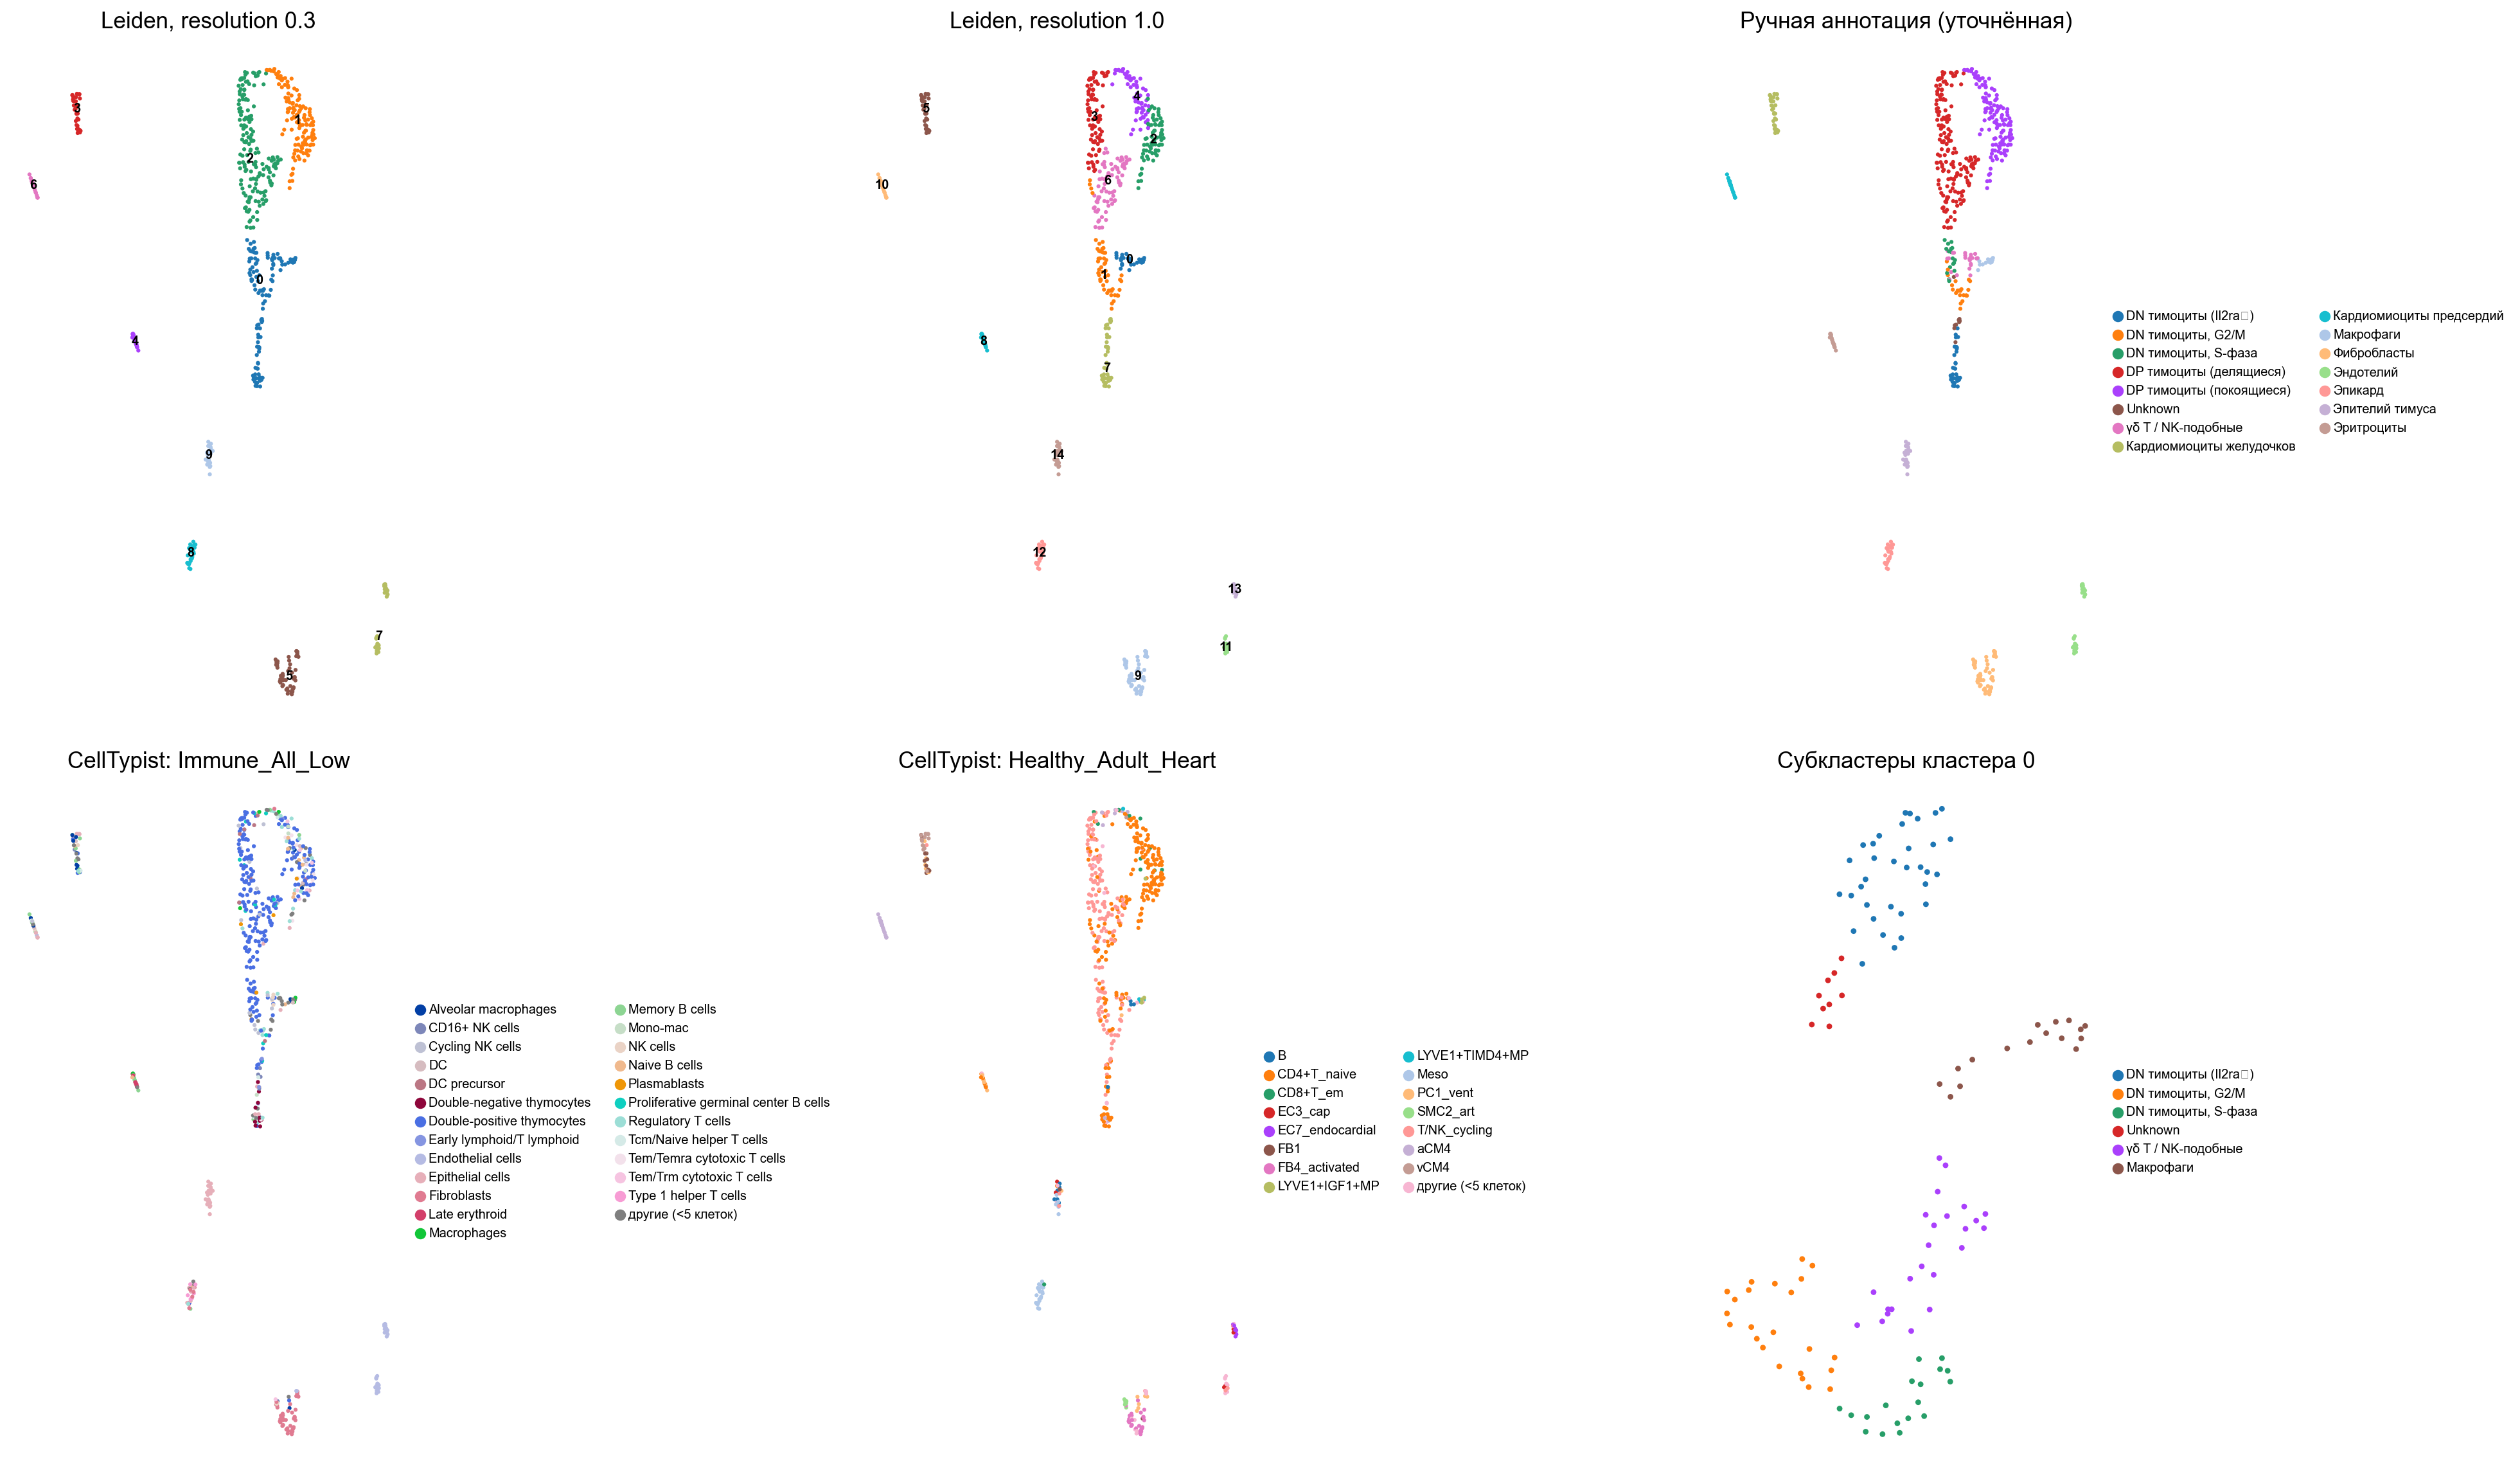

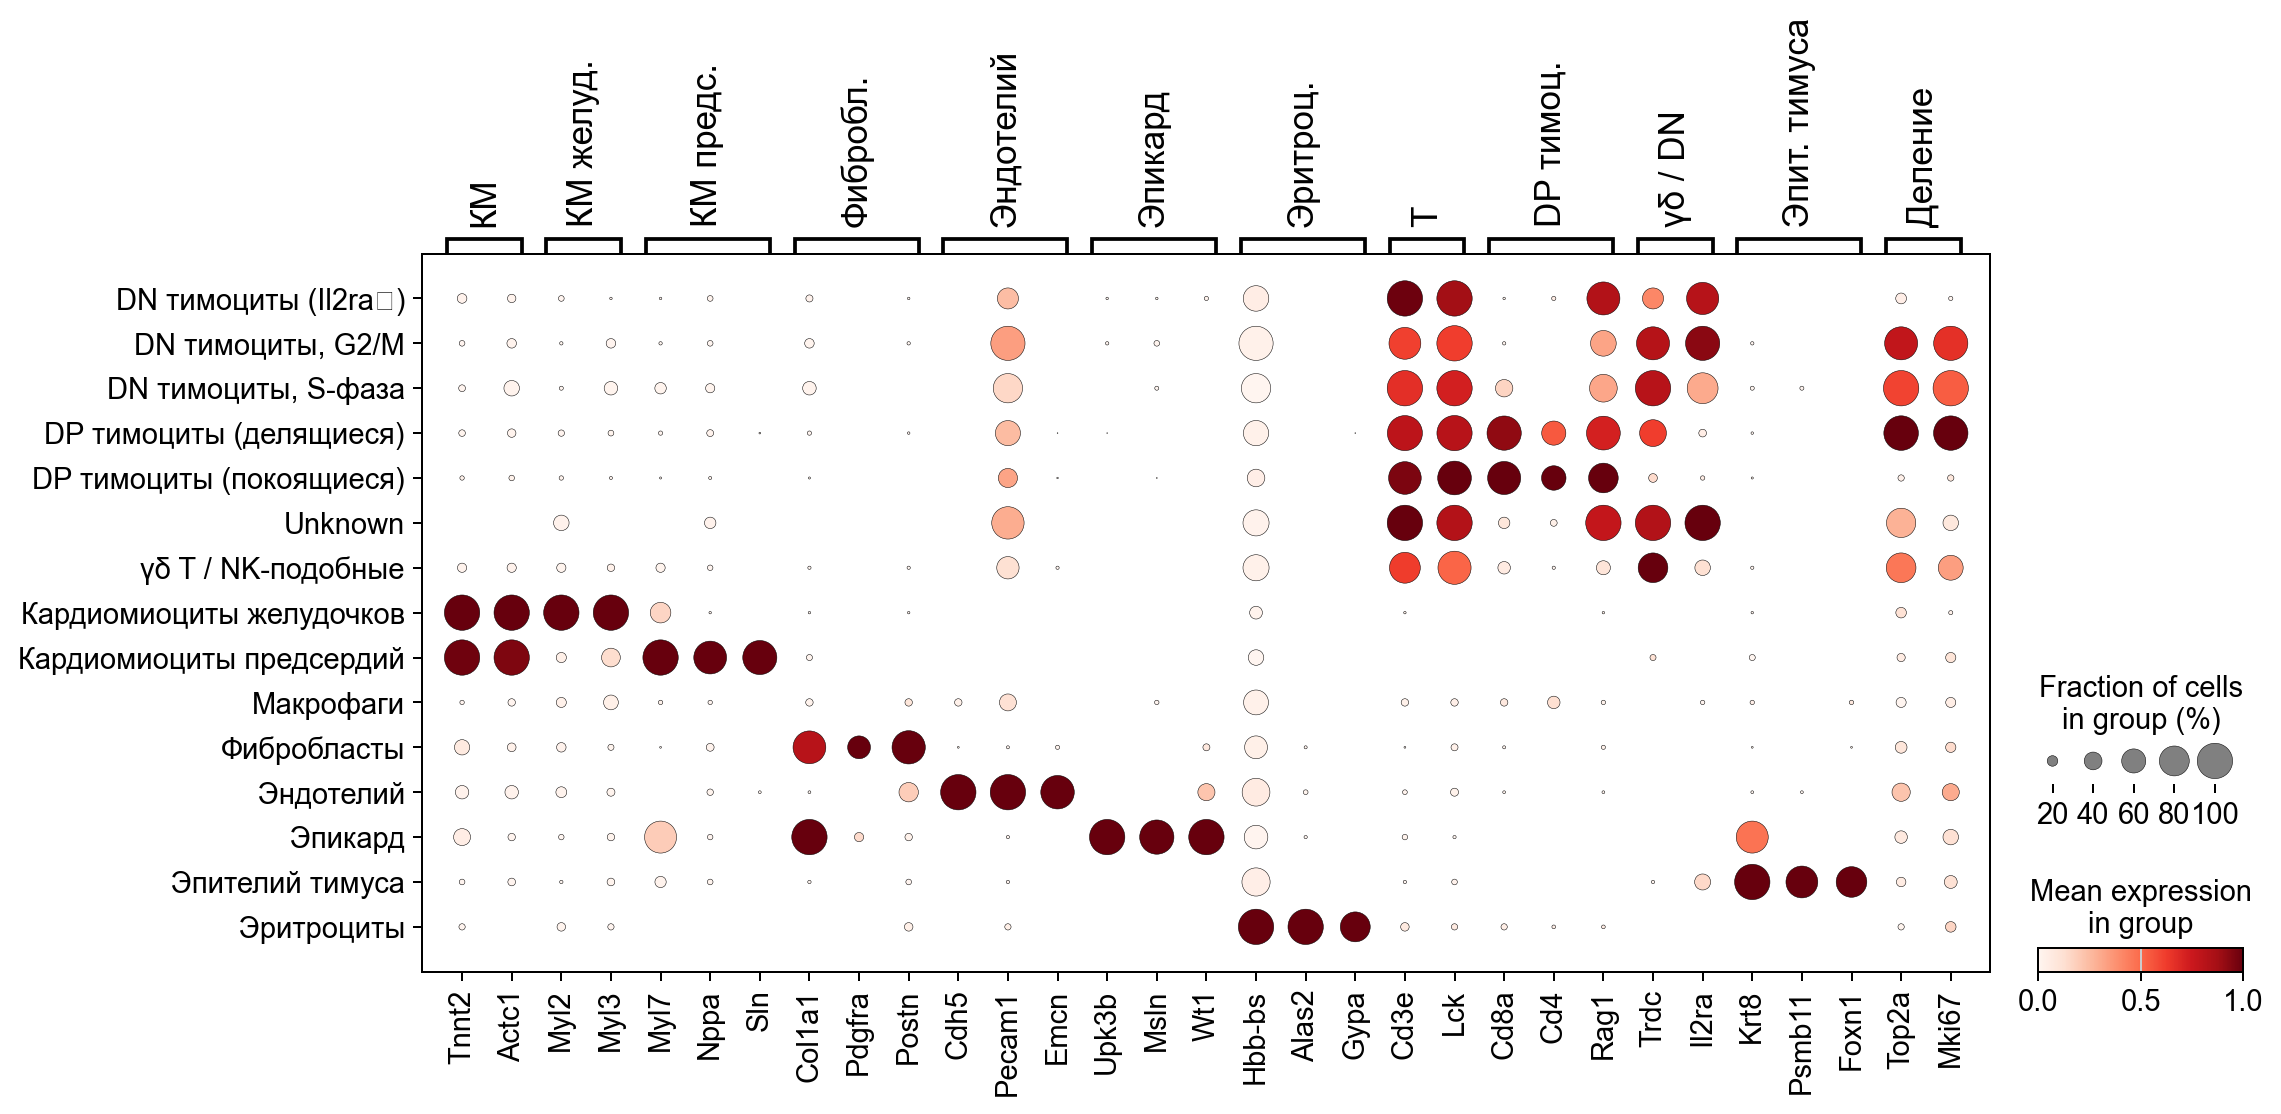

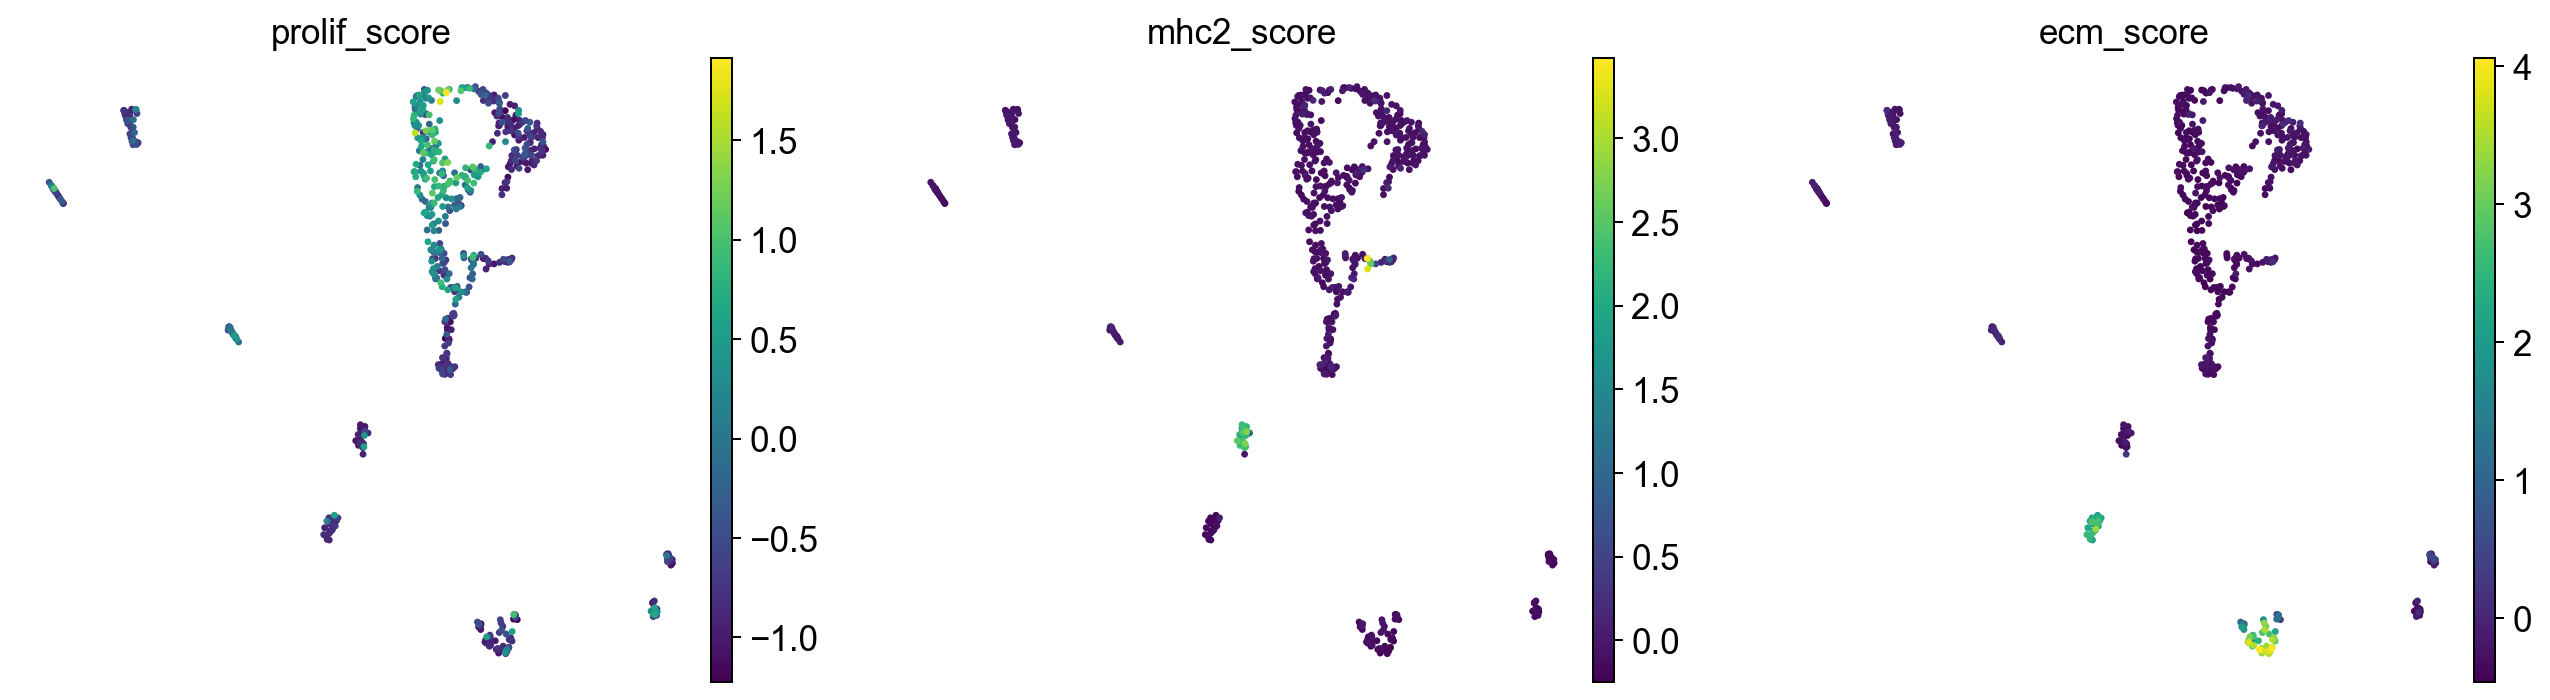

In [37]:
fig, axes = plt.subplots(2, 3, figsize=(22, 13))
panels = [("leiden_0.3", "Leiden, resolution 0.3"), ("leiden_1.0", "Leiden, resolution 1.0"),
          ("refined_cell_type", "Ручная аннотация (уточнённая)"),
          ("ct_immune_main", "CellTypist: Immune_All_Low"), ("ct_heart_main", "CellTypist: Healthy_Adult_Heart")]
for ax, (col, title) in zip(axes.ravel(), panels):
    on_data = col.startswith("leiden")
    sc.pl.umap(heart, color=col, ax=ax, show=False, size=25, title=title,
               legend_loc="on data" if on_data else "right margin", legend_fontsize=8)
sc.pl.umap(sub, color="sub_cell_type", ax=axes[1, 2], show=False, size=50,
           title=f"Субкластеры кластера {SUB_CLUSTER}", legend_fontsize=8)
plt.tight_layout(); plt.show()

sc.pl.dotplot(heart, LIT_MARKERS, groupby="refined_cell_type", standard_scale="var", use_raw=False)
sc.pl.umap(heart, color=list(PROGRAMS), ncols=3, size=30, cmap="viridis")

### Заключение

1. **Найденные популяции.**
   - Клетки сердца: кардиомиоциты желудочков и предсердий, фибробласты, эндотелий, эпикард.
   - Кровь: эритроциты и макрофаги.
   - Большая группа клеток **тимуса**: DP-тимоциты (покоящиеся и делящиеся), DN-тимоциты, γδ T-клетки и эпителий тимуса. Вероятно, это примесь соседнего органа при выделении сердца.
2. **Ключевые маркеры:**
   - КМ: `Tnnt2`, `Actc1`, желудочковые `Myl2`/`Myl3`, предсердные `Myl7`/`Nppa`/`Sln`;
   - фибробласты: `Col1a1`, `Pdgfra`, `Postn`;
   - эндотелий: `Cdh5`, `Pecam1`, `Emcn`;
   - эпикард: `Upk3b`, `Msln`, `Wt1`;
   - эритроциты: `Hbb-bs`, `Alas2`, `Gypa`;
   - тимоциты: `Cd3e`, `Cd8a`, `Cd4`, `Rag1`, `Il2ra`, `Trdc`;
   - эпителий тимуса: `Psmb11`, `Krt8`, `Foxn1`;
   - макрофаги: `C1qa/b/c`, `Aif1`.
3. **Согласие с CellTypist** хорошее там, где ткань и тип клеток есть в референсе. Модель сердца уверенно узнаёт КМ, эпикард, фибробласты и эндотелий, модель иммунных клеток — DP-тимоциты, фибробласты, эндотелий и эпителий. Плохое — там, где референс не подходит: тимоциты в модели сердца, клетки сердца в иммунной модели. Причины: перенос с человека на мышь, взрослый референс против эмбриона, закрытый набор классов.
4. **Субкластеризация** «смешанного» кластера 0 разделила его на γδ T-клетки, DN-тимоциты (с отдельными S- и G2/M-состояниями) и **макрофаги**. Макрофаги при общей кластеризации были не видны из-за малого числа клеток (16).
5. **Генные программы** отделили состояние от типа (пролиферация у DP- и DN-тимоцитов), подтвердили антигенпрезентирующие клетки (MHC II у эпителия тимуса и макрофагов) и строму (ECM у фибробластов и эпикарда). Тем самым они независимо подтвердили ручную аннотацию.

In [38]:
# Сохранение результатов
heart.write_h5ad(DATA_DIR / "heart_E18_annotated.h5ad", compression="gzip")
sub.write_h5ad(DATA_DIR / f"heart_E18_cluster{SUB_CLUSTER}_subclustered.h5ad", compression="gzip")